# Tarea 2 — Inteligencia Artificial



- Integrantes: Andrés Hormazabal, sección 1 , Héctor Vines, sección 2.
- Profesor: Johan Fuentes. 
- Ayudantes: Dante Libiot, Miguel Pereira, Matias Vasquez.
- URL del dataset utilizado para la pregunta 1: https://www.kaggle.com/datasets/saichaitanyareddyai/spotify-tracks-dataset-audio-features

- URL del dataset utilizado para la pregunta 2: https://www.kaggle.com/datasets/fedesoriano/stellar-classification-dataset-sdss17


---
# 0. Configuración inicial

Importación de librerías y carga de los datasets (descarga online o desde el proyecto).


In [1]:
import os                                  
import pandas as pd                        
import numpy as np                         
from matplotlib import pyplot as plt        
from pandas.plotting import scatter_matrix  
from collections import Counter            
import time                                
import kagglehub
import seaborn as sns
from sklearn.model_selection import train_test_split    
from sklearn.model_selection import cross_val_score     
from sklearn.model_selection import StratifiedKFold     
from sklearn.preprocessing import StandardScaler, add_dummy_feature
from sklearn.pipeline        import make_pipeline       
from sklearn.linear_model import LinearRegression      
from sklearn.linear_model import LogisticRegression     
from sklearn.linear_model import Ridge, Lasso           
from sklearn.svm          import SVC, LinearSVC         
from sklearn.cluster      import KMeans, DBSCAN         
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import mutual_info_regression
from sklearn.metrics import r2_score                   
from sklearn.metrics import mean_absolute_error        
from sklearn.metrics import mean_squared_error         
from sklearn.metrics import root_mean_squared_error     
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, classification_report
from pathlib import Path
import sys
import warnings
import sklearn
from IPython import get_ipython
from IPython.display import Markdown, display
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import ConfusionMatrixDisplay


/Users/andres/Desktop/tarea2IA/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path_sdss_dir = kagglehub.dataset_download("fedesoriano/stellar-classification-dataset-sdss17")
df_sd = pd.read_csv(os.path.join(path_sdss_dir, "star_classification.csv"))
print("Dataset SDSS17 cargado:", df_sd.shape)


Dataset SDSS17 cargado: (100000, 18)


---
# PREGUNTA 1 (30 puntos) — Aprendizaje supervisado

**Enunciado:** aplicar regresión lineal (variable continua $Y_1$) y regresión logística (variable binaria $Y_2$) sobre un dataset de ≥20.000 filas y ≥12 columnas, con las mismas 10 variables predictoras $X_1,\dots,X_{10}$ y partición 70% / 15% / 15%. Para cada tarea se entrenan tres versiones (10, 5 y 3 variables más relevantes, seleccionadas solo con datos de entrenamiento), se comparan en entrenamiento y validación, y solo las dos mejores se evalúan en prueba. Finalmente se analiza la influencia del número de variables en el desempeño y la generalización (overfitting / underfitting).

**Contenido:**
- 1.0 Dataset y variables
- 1.1 Selección de variables objetivo y predictoras
- 1.2 División del dataset
- **1.A** Regresión lineal ($Y_1$): selección de variables, entrenamiento, comparación, evaluación en prueba
- **1.B** Regresión logística ($Y_2$): selección de variables, entrenamiento, comparación, evaluación en prueba
- **1.C** Análisis final de la Pregunta 1


In [3]:
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': False})
pd.set_option('display.max_columns', 20)
seed = 42

predictorias = [
    'duration_ms', 'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'tempo', 'valence',
]
objetivo_y1 = 'popularity'
objetivo_y2 = 'explicit'
columnas_modelado = predictorias + [objetivo_y1, objetivo_y2]

nombre_csv = 'spotify-tracks-dataset-detailed.csv'
directorio = Path(kagglehub.dataset_download(
    'saichaitanyareddyai/spotify-tracks-dataset-audio-features'
))
spotify_file = directorio / nombre_csv

df_spotify = pd.read_csv(spotify_file)
assert set(['track_id'] + columnas_modelado).issubset(df_spotify.columns)
assert df_spotify.shape[0] >= 20_000 and len(columnas_modelado) == 12
assert len(set(predictorias)) == 10
assert objetivo_y1 not in predictorias and objetivo_y2 not in predictorias
print('CSV:', spotify_file)
print('Dataset original:', df_spotify.shape)
print('Python:', sys.version.split()[0])
print('scikit-learn:', sklearn.__version__)


CSV: /Users/andres/.cache/kagglehub/datasets/saichaitanyareddyai/spotify-tracks-dataset-audio-features/versions/1/spotify-tracks-dataset-detailed.csv
Dataset original: (114000, 20)
Python: 3.14.7
scikit-learn: 1.9.1


## 1.0 Dataset y variables

Se utiliza el dataset de pistas de Spotify citado en la portada. Cada registro
describe una pista y sus características musicales. Se abordan dos tareas de
aprendizaje supervisado: estimar su popularidad y clasificar su contenido explícito.

| # | Columna | Descripción | Tipo |
|---|---|---|---|
| 0 | track_id | Identificador único de la pista en Spotify | Categórica (texto) |
| 1 | artists | Artista(s) que interpretan la pista, separados por ; | Categórica (texto) |
| 2 | album_name | Nombre del álbum en que aparece la pista | Categórica (texto) |
| 3 | track_name | Nombre de la pista | Categórica (texto) |
| 4 | popularity | Popularidad de la pista (0 a 100), según reproducciones recientes | Numérica discreta |
| 5 | duration_ms | Duración de la pista en milisegundos | Numérica continua |
| 6 | explicit | Indica si la pista tiene contenido explícito | Binaria (booleana) |
| 7 | danceability | Qué tan bailable es la pista (0.0 a 1.0) | Numérica continua |
| 8 | energy | Intensidad y actividad percibida de la pista (0.0 a 1.0) | Numérica continua |
| 9 | key | Tonalidad de la pista (0 = Do, 1 = Do#, ..., 11 = Si) | Categórica (codificada numéricamente) |
| 10 | loudness | Volumen promedio de la pista en decibelios (dB) | Numérica continua |
| 11 | mode | Modalidad de la pista (1 = mayor, 0 = menor) | Binaria |
| 12 | speechiness | Presencia de palabras habladas en la pista (0.0 a 1.0) | Numérica continua |
| 13 | acousticness | Confianza de que la pista sea acústica (0.0 a 1.0) | Numérica continua |
| 14 | instrumentalness | Probabilidad de que la pista no contenga voz (0.0 a 1.0) | Numérica continua |
| 15 | liveness | Probabilidad de que la pista sea una grabación en vivo (0.0 a 1.0) | Numérica continua |
| 16 | valence | Positividad musical transmitida por la pista (0.0 a 1.0) | Numérica continua |
| 17 | tempo | Tempo estimado de la pista en pulsos por minuto (BPM) | Numérica continua |
| 18 | time_signature | Compás estimado de la pista (pulsos por compás) | Numérica discreta |
| 19 | track_genre | Género musical asociado a la pista | Categórica (texto) |

### 1.1 Objetivos y diez predictoras iniciales

Se mantiene **Y₁ = `popularity`** como respuesta cuantitativa de regresión y
**Y₂ = `explicit`** como etiqueta binaria (1: explícita; 0: no explícita).
La popularidad mide alcance, mientras que `explicit` identifica una propiedad del
contenido; son objetivos distintos y requieren selecciones de variables separadas.

Las diez predictoras iniciales son `duration_ms`, `danceability`, `energy`,
`loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`,
`tempo` y `valence`. Se usan exactamente las mismas diez en ambas tareas.

Se excluyen identificadores y texto. También se dejan fuera `key`, `mode` y
`time_signature` para mantener la selección inicial de características continuas:
`key` tiene estructura circular, `mode` es otra variable binaria y el compás es
discreto. La elección de `explicit` se justifica por la tarea de contenido, no por
ser la única variable binaria. Las asociaciones acústicas con ambos objetivos
se investigan empíricamente, sin presuponer que sean nulas ni causales.

### 1.2 Limpieza y división 70/15/15

Se conserva la primera aparición de cada `track_id` para evitar que la misma pista
quede repetida entre particiones. Se mantienen los filtros previos sobre ceros
en `tempo`, `danceability` y `duration_ms`; por tanto, el alcance del estudio
queda limitado a canciones con esas tres características distintas de cero.
Un valor cero no demuestra por sí solo un error, y estos filtros constituyen
una decisión de inclusión heredada, no una prueba de invalidez universal.

**Se retira el filtro de popularidad:** las pistas con `popularity = 0` se
conservan si cumplen los demás criterios. Se verifican explícitamente nulos y
valores finitos en las doce columnas de modelado. Los nulos en texto no usado
no requieren eliminar registros ni imputar información para estos modelos.

In [4]:
nulos_modelado = df_spotify[columnas_modelado].isna().sum()
display(nulos_modelado.rename('nulos_modelado').to_frame())
assert nulos_modelado.sum() == 0, 'Hay nulos en columnas utilizadas por los modelos.'

df_sin_duplicados = df_spotify.drop_duplicates(subset='track_id', keep='first').copy()
mask_valid = (
    (df_sin_duplicados['tempo'] != 0)
    & (df_sin_duplicados['danceability'] != 0)
    & (df_sin_duplicados['duration_ms'] != 0)
)
df_clean = df_sin_duplicados.loc[mask_valid].copy()
df_clean['explicit'] = df_clean['explicit'].astype(int)

conteos_limpieza = pd.DataFrame({
    'etapa': ['Original', 'Una fila por track_id', 'Filtros tempo/danceability/duración'],
    'filas': [len(df_spotify), len(df_sin_duplicados), len(df_clean)],
})
conteos_limpieza['eliminadas_en_etapa'] = (
    conteos_limpieza['filas'].shift(1) - conteos_limpieza['filas']
).fillna(0).astype(int)
display(conteos_limpieza)

estadisticas = pd.DataFrame({
    'original': df_spotify['popularity'].agg(['count', 'mean', 'std', 'min', 'max']),
    'limpio': df_clean['popularity'].agg(['count', 'mean', 'std', 'min', 'max']),
})
display(estadisticas.round(4))
n_ceros_conservados = int(df_clean['popularity'].eq(0).sum())
assert n_ceros_conservados == int(
    (mask_valid & df_sin_duplicados['popularity'].eq(0)).sum()
)
assert n_ceros_conservados > 0
assert len(df_clean) >= 20_000
assert df_clean['track_id'].is_unique
assert np.isfinite(df_clean[columnas_modelado].to_numpy(dtype=float)).all()
assert set(df_clean['explicit'].unique()) == {0, 1}


,nulos_modelado
duration_ms,0
danceability,0
energy,0
loudness,0
speechiness,0
acousticness,0
instrumentalness,0
liveness,0
tempo,0
valence,0


,etapa,filas,eliminadas_en_etapa
0,Original,114000,0
1,Una fila por track_id,89741,24259
2,Filtros tempo/danceability/duración,89583,158


,original,limpio
count,114000.0000,89583.0000
mean,33.2385,33.1918
std,22.3051,20.5928
min,0.0000,0.0000
max,100.0000,100.0000


Se pasa de **114,000** a **89,583** filas. Se conservan **9,443** pistas con popularidad cero. La media de popularidad cambia de **33.24** a **33.19** y su desviación muestral de **22.31** a **20.59**. La proporción explícita en la base limpia es **8.60%**.

In [5]:
split_test = 0.15
split_val = 0.15
split_relative_val = split_val / (1 - split_test)

temp, df_test = train_test_split(df_clean, test_size=split_test, random_state=seed)
df_train, df_val = train_test_split(
    temp, test_size=split_relative_val, random_state=seed
)
particiones = {'train': df_train, 'val': df_val, 'test': df_test}
resumen_particiones = pd.DataFrame([
    {
        'conjunto': nombre,
        'filas': len(datos),
        'proporcion': len(datos) / len(df_clean),
        'media_popularity': datos['popularity'].mean(),
        'desviacion_popularity': datos['popularity'].std(),
        'proporcion_explicit': datos['explicit'].mean(),
    }
    for nombre, datos in particiones.items()
])
display(resumen_particiones.round(6))

ids = {nombre: set(datos['track_id']) for nombre, datos in particiones.items()}
assert sum(map(len, particiones.values())) == len(df_clean)
assert ids['train'].isdisjoint(ids['val'])
assert ids['train'].isdisjoint(ids['test'])
assert ids['val'].isdisjoint(ids['test'])
assert set.union(*ids.values()) == set(df_clean['track_id'])
assert np.allclose(resumen_particiones['proporcion'], [0.70, 0.15, 0.15], atol=2/len(df_clean))
assert all(set(datos['explicit'].unique()) == {0, 1} for datos in particiones.values())
print('Particiones completas, sin pistas compartidas y con ambas clases presentes.')


,conjunto,filas,proporcion,media_popularity,desviacion_popularity,proporcion_explicit
0,train,62707,0.699988,33.210359,20.609690,0.086035
1,val,13438,0.150006,33.267971,20.649987,0.086397
2,test,13438,0.150006,33.029022,20.456887,0.085429


Particiones completas, sin pistas compartidas y con ambas clases presentes.


**Nota sobre el código:** La división es aleatoria y **sin estratificación**, con el mismo procedimiento usado previamente.

## 1.A — Regresión lineal para `popularity`

### 1.A.1 Selección de variables con entrenamiento

Se ordenan las diez predictoras por el valor absoluto de su correlación de Pearson
con `popularity` en `df_train`; se conserva el signo para interpretar la dirección.
Ante un empate exacto se ordena alfabéticamente. Los primeros cinco y tres
elementos definen subconjuntos anidados. Pearson describe asociación lineal
individual: no identifica causalidad, relaciones no lineales ni contribuciones
condicionales. La correlación individual máxima no fija un techo para el R²
de una regresión multivariada.

In [6]:
correlacion_y1 = df_train[predictorias].corrwith(df_train[objetivo_y1])
ranking_y1 = (
    pd.DataFrame({
        'variable': correlacion_y1.index,
        'correlacion': correlacion_y1.to_numpy(),
        'abs_correlacion': correlacion_y1.abs().to_numpy(),
    })
    .sort_values(['abs_correlacion', 'variable'], ascending=[False, True], kind='stable')
    .reset_index(drop=True)
)
assert ranking_y1['correlacion'].notna().all()
listFive = ranking_y1['variable'].head(5).tolist()
listThree = ranking_y1['variable'].head(3).tolist()
configs = {'complete': predictorias.copy(), 'reduce': listFive, 'min': listThree}
assert set(listThree) <= set(listFive) <= set(predictorias)
display(ranking_y1.round(6))


,variable,correlacion,abs_correlacion
0,instrumentalness,-0.129150,0.129150
1,loudness,0.075280,0.075280
2,danceability,0.066621,0.066621
3,speechiness,-0.045205,0.045205
4,acousticness,-0.040929,0.040929
5,duration_ms,-0.023108,0.023108
6,energy,0.017335,0.017335
7,liveness,-0.015712,0.015712
8,tempo,0.010611,0.010611
9,valence,-0.008018,0.008018


**Cinco variables:** instrumentalness, loudness, danceability, speechiness, acousticness.

**Tres variables:** instrumentalness, loudness, danceability.

La selección es empírica y univariada: prioriza asociaciones individuales con la popularidad. No implica que las variables descartadas carezcan de aportes cuando se combinan con otras.

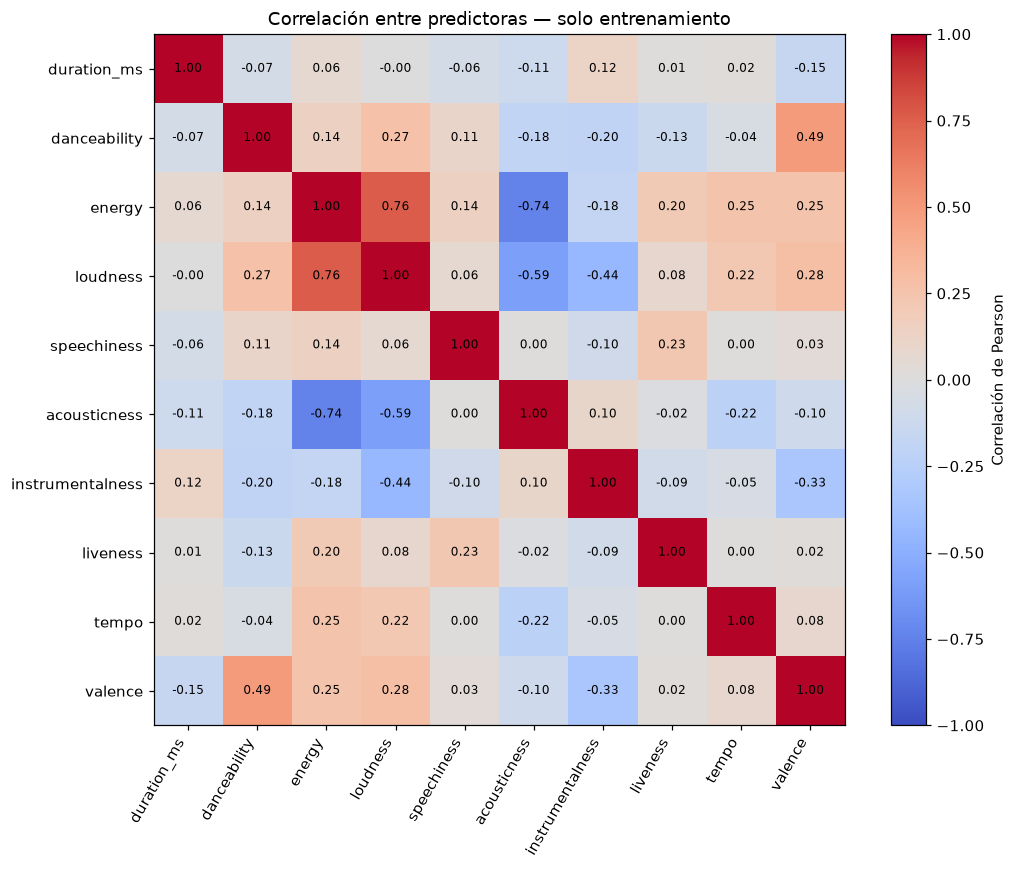

In [7]:
corr_predictoras = df_train[predictorias].corr()
fig, ax = plt.subplots(figsize=(10, 8))
imagen = ax.imshow(corr_predictoras, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(10), predictorias, rotation=60, ha='right')
ax.set_yticks(range(10), predictorias)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f'{corr_predictoras.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(imagen, ax=ax, label='Correlación de Pearson')
ax.set_title('Correlación entre predictoras — solo entrenamiento')
plt.tight_layout()
plt.show()


### 1.A.2 Entrenamiento de las versiones de 10, 5 y 3 variables

Cada versión ajusta un `StandardScaler` y una `LinearRegression` dentro de un
pipeline usando únicamente entrenamiento. El modelo es

\[\hat y = \theta_0 + \sum_{j=1}^{p}\theta_j z_j, \qquad J(\theta)=\frac{1}{2m}\sum_{i=1}^(\hat y^{(i)}-y^{(i)})^2\]

donde \(z_j\) es la característica estandarizada. Para estos datos densos,
`LinearRegression` resuelve mínimos cuadrados mediante `lstsq`, sin calcular
explícitamente la inversa de \(X^\top X\). La expresión de la ecuación normal
es una formulación teórica cuando la matriz es invertible; no describe literalmente
la implementación de `.fit()`.

Los coeficientes mostrados corresponden a un aumento de una desviación estándar
de la predictora, manteniendo las demás fijas. La estandarización permite comparar
escalas, pero no elimina multicolinealidad ni otorga interpretación causal.

In [8]:
def evaluar_regresion(y_real, pred):
    return {
        'R2': r2_score(y_real, pred),
        'RMSE': root_mean_squared_error(y_real, pred),
        'MAE': mean_absolute_error(y_real, pred),
    }

y1_train = df_train[objetivo_y1]
y1_val = df_val[objetivo_y1]
models = {}
results = []
parametros_y1 = []

for version, cols in configs.items():
    pipe = make_pipeline(StandardScaler(), LinearRegression())
    pipe.fit(df_train[cols], y1_train)
    models[version] = pipe
    fila = {'version': version, 'n_vars': len(cols)}
    for conjunto, datos, objetivo in [
        ('train', df_train, y1_train), ('val', df_val, y1_val)
    ]:
        metricas = evaluar_regresion(objetivo, pipe.predict(datos[cols]))
        fila.update({f'{metrica}_{conjunto}': valor for metrica, valor in metricas.items()})
    results.append(fila)
    ajuste = pipe.named_steps['linearregression']
    parametros_y1.append({'version': version, 'variable': 'intercepto', 'coeficiente': ajuste.intercept_})
    parametros_y1.extend(
        {'version': version, 'variable': col, 'coeficiente': coef}
        for col, coef in zip(cols, ajuste.coef_)
    )

table = pd.DataFrame(results)
display(pd.DataFrame(parametros_y1).round(6))


,version,variable,coeficiente
0,complete,intercepto,33.210359
1,complete,duration_ms,-0.446926
2,complete,danceability,1.817208
3,complete,energy,-0.452697
4,complete,loudness,0.470365
5,complete,speechiness,-1.325627
6,complete,acousticness,-0.499330
7,complete,instrumentalness,-2.898726
8,complete,liveness,0.015595
9,complete,tempo,0.237744


### 1.A.3 Comparación en entrenamiento y validación

Se reportan R² (mayor es mejor), RMSE y MAE (menor es mejor, en puntos de
popularidad). R² puede ser negativo si el modelo es peor que la referencia
de la media del conjunto evaluado. Como baseline predictivo se ajusta un
`DummyRegressor` con la media de **entrenamiento**, aplicando esa misma constante
a validación. La referencia no aprende la media de validación.

In [9]:
baseline_y1 = DummyRegressor(strategy='mean').fit(df_train[predictorias], y1_train)
filas_baseline_y1 = []
for conjunto, datos, objetivo in [
    ('train', df_train, y1_train), ('val', df_val, y1_val)
]:
    filas_baseline_y1.append({
        'conjunto': conjunto,
        **evaluar_regresion(objetivo, baseline_y1.predict(datos[predictorias])),
    })
tabla_baseline_y1 = pd.DataFrame(filas_baseline_y1).set_index('conjunto')
table['brecha_R2'] = table['R2_train'] - table['R2_val']
display(table.round(6))
display(tabla_baseline_y1.round(6))

for conjunto, objetivo in [('train', y1_train), ('val', y1_val)]:
    varianza = objetivo.var(ddof=0)
    assert np.allclose(table[f'R2_{conjunto}'], 1 - table[f'RMSE_{conjunto}']**2 / varianza)
    assert (table[f'RMSE_{conjunto}'] >= table[f'MAE_{conjunto}'] - 1e-10).all()
assert (np.diff(table['R2_train']) <= 1e-10).all()

orden_y1 = table.sort_values(
    ['R2_val', 'n_vars', 'version'], ascending=[False, True, True], kind='stable'
)
mejores_y1 = orden_y1['version'].head(2).tolist()
res_y1 = table.set_index('version')
mejor_y1 = orden_y1.iloc[0]
rmse_baseline_val = tabla_baseline_y1.loc['val', 'RMSE']
mejora_rmse_y1 = 1 - mejor_y1['RMSE_val'] / rmse_baseline_val
caida_10_5 = res_y1.loc['complete', 'R2_val'] - res_y1.loc['reduce', 'R2_val']
caida_5_3 = res_y1.loc['reduce', 'R2_val'] - res_y1.loc['min', 'R2_val']
brechas_y1 = '; '.join(
    f"{fila.version}: {fila.brecha_R2:.5f}" for fila in table.itertuples()
)


,version,n_vars,R2_train,RMSE_train,MAE_train,R2_val,RMSE_val,MAE_val,brecha_R2
0,complete,10,0.030716,20.290534,16.714511,0.032589,20.309968,16.749437,-0.001872
1,reduce,5,0.022696,20.374310,16.864474,0.022692,20.413585,16.908450,0.000003
2,min,3,0.018605,20.416903,16.977155,0.018456,20.457777,17.024529,0.000149


,R2,RMSE,MAE
conjunto,,,
train,0.000000,20.609526,17.262552
val,-0.000008,20.649299,17.276791


**Nivel de desempeño.** La mejor versión en validación es **complete**,
con R² = **0.0326**, RMSE = **20.310** y
MAE = **16.749**. El baseline de media obtiene RMSE =
**20.649**; la reducción relativa de RMSE es **1.64%**.
Esta referencia permite valorar el aporte del modelo sin confundir estabilidad
entre conjuntos con alta capacidad predictiva.

**Generalización.** Las brechas R² de entrenamiento menos validación son
**complete: -0.00187; reduce: 0.00000; min: 0.00015**. En la versión completa, R² es
**0.0307** en entrenamiento y **0.0326**
en validación: no aparece una ventaja marcada del entrenamiento. El R² bajo
en ambos y la mejora de RMSE de **1.64%** frente a la media
muestran capacidad predictiva limitada con estas características y este modelo.
La cercanía entre conjuntos no basta para identificar la causa de esa limitación.

**Cantidad de variables.** El cambio de R² en validación al pasar de 10 a 5 es
**+0.00990**, y de 5 a 3 es **+0.00424** (valor positivo indica
caída). Reducir variables modifica tanto la complejidad como la información
disponible. En esta partición las tres métricas de validación favorecen conservar
las diez variables; la pérdida de R² de 10 a 5 es mayor que la de 5 a 3.
El ranking univariado no garantiza conservar las mejores combinaciones y puede
descartar variables que aportan información condicional. Las diferencias
observadas no establecen una regla general para otras particiones.

**Selección fijada antes de prueba:** mayor R² en validación; ante empate exacto,
menor cantidad de variables y luego nombre de versión. Las versiones elegidas son
**complete, reduce**.

**Nota sobre el código:** Las identidades de verificación usan la varianza poblacional (`ddof=0`) del mismo conjunto, no `std()` con `ddof=1`.

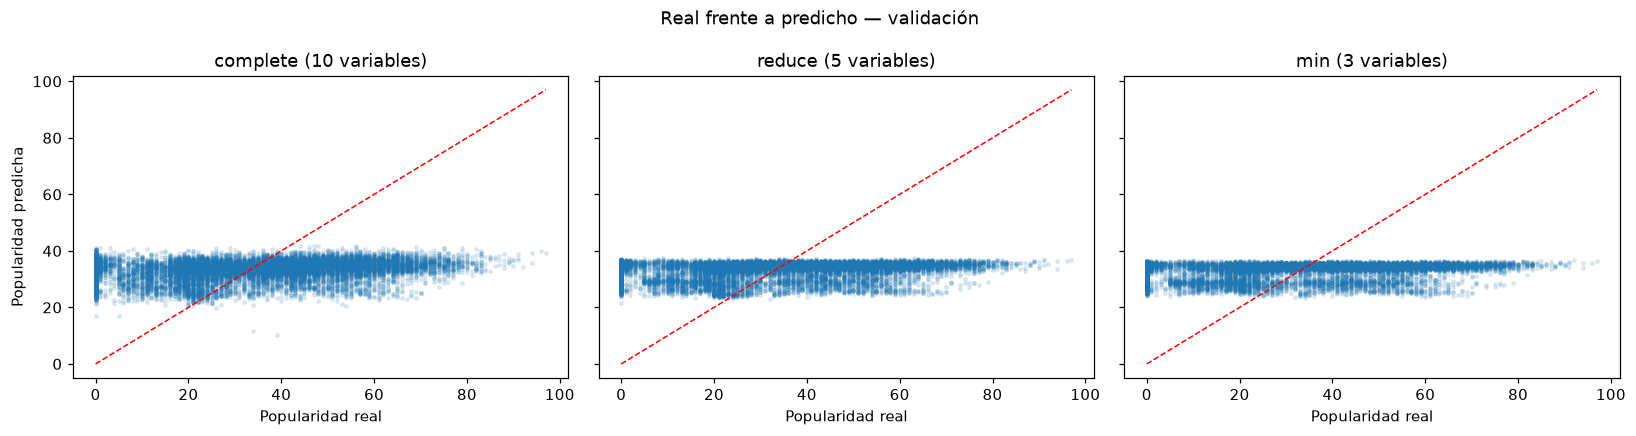

In [10]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, (version, cols) in zip(ejes, configs.items()):
    pred = models[version].predict(df_val[cols])
    ax.scatter(y1_val, pred, s=5, alpha=0.12)
    limites = [min(y1_val.min(), pred.min()), max(y1_val.max(), pred.max())]
    ax.plot(limites, limites, 'r--', linewidth=1)
    ax.set_title(f'{version} ({len(cols)} variables)')
    ax.set_xlabel('Popularidad real')
ejes[0].set_ylabel('Popularidad predicha')
fig.suptitle('Real frente a predicho — validación')
plt.tight_layout()
plt.show()


### 1.A.4 Prueba de las dos mejores versiones lineales

Las versiones ya se eligieron en validación. Se aplican los pipelines entrenados,
sin ejecutar `.fit()` ni modificar columnas o parámetros después de ver prueba.

In [11]:
y1_test = df_test[objetivo_y1]
tabla_test_y1 = pd.DataFrame([
    {
        'version': version,
        'n_vars': len(configs[version]),
        **{f'{metrica}_test': valor for metrica, valor in evaluar_regresion(
            y1_test, models[version].predict(df_test[configs[version]])
        ).items()},
    }
    for version in mejores_y1
])
comparacion_test_y1 = tabla_test_y1.merge(
    table[['version', 'R2_val', 'RMSE_val', 'MAE_val']], on='version', validate='one_to_one'
)
comparacion_test_y1['cambio_R2_test_val'] = (
    comparacion_test_y1['R2_test'] - comparacion_test_y1['R2_val']
)
display(comparacion_test_y1.round(6))
detalle_prueba_y1 = '; '.join(
    f"{f.version}: R² validación {f.R2_val:.4f}, prueba {f.R2_test:.4f} "
    f"(cambio {f.cambio_R2_test_val:+.4f})"
    for f in comparacion_test_y1.itertuples()
)


,version,n_vars,R2_test,RMSE_test,MAE_test,R2_val,RMSE_val,MAE_val,cambio_R2_test_val
0,complete,10,0.032671,20.119189,16.589625,0.032589,20.309968,16.749437,0.000083
1,reduce,5,0.022793,20.221657,16.763151,0.022692,20.413585,16.908450,0.000100


**Contraste con validación.** complete: R² validación 0.0326, prueba 0.0327 (cambio +0.0001); reduce: R² validación 0.0227, prueba 0.0228 (cambio +0.0001). La diferencia estima la variación entre estas particiones; una sola división no proporciona intervalos de incertidumbre ni demuestra estabilidad en otras poblaciones. Los resultados de prueba se reportan sin usarlos para revisar la selección.

## 1.B — Regresión logística para `explicit`

### 1.B.1 Selección de variables con entrenamiento

Se calcula, para cada predictora, la diferencia absoluta entre su media en la
clase 1 y en la clase 0, dividida por su desviación estándar muestral en todo
entrenamiento. La estandarización evita que las unidades dominen el ranking.
Los empates exactos se resuelven alfabéticamente. Las listas de cinco y tres
variables se obtienen de este ranking nuevo y usan nombres distintos a las de Y₁.

El criterio mide separación de medias y puede omitir relaciones que no cambian
el promedio. Es una selección univariada, no una garantía de la mejor combinación.
Pearson con una etiqueta binaria equivale a la correlación punto-biserial y también
es válido para describir esa asociación; no se descarta por el tipo binario.

In [12]:
y2_train = df_train[objetivo_y2]
y2_val = df_val[objetivo_y2]
medias_y2 = df_train.groupby(objetivo_y2)[predictorias].mean()
desviaciones_y2 = df_train[predictorias].std(ddof=1)
assert (desviaciones_y2 > 0).all(), 'El ranking requiere predictoras no constantes.'
diferencias_y2 = medias_y2.loc[1] - medias_y2.loc[0]
ranking_y2 = pd.DataFrame({
    'variable': predictorias,
    'media_no_explicita': medias_y2.loc[0, predictorias].to_numpy(),
    'media_explicita': medias_y2.loc[1, predictorias].to_numpy(),
    'diferencia_con_signo': diferencias_y2.loc[predictorias].to_numpy(),
    'desviacion_train': desviaciones_y2.loc[predictorias].to_numpy(),
    'puntaje': (diferencias_y2.abs() / desviaciones_y2).loc[predictorias].to_numpy(),
}).sort_values(['puntaje', 'variable'], ascending=[False, True], kind='stable').reset_index(drop=True)

lista_5_y2 = ranking_y2['variable'].head(5).tolist()
lista_3_y2 = ranking_y2['variable'].head(3).tolist()
configs_y2 = {'complete': predictorias.copy(), 'reduce': lista_5_y2, 'min': lista_3_y2}
assert set(lista_3_y2) <= set(lista_5_y2) <= set(predictorias)
assert configs['reduce'] == listFive and configs['min'] == listThree
display(ranking_y2.round(6))

sentido_variables = {
    'duration_ms': 'la duración describe la extensión de la pista, sin indicar por sí sola el lenguaje utilizado',
    'danceability': 'la bailabilidad puede recoger asociaciones con estilos y repertorios',
    'energy': 'la energía caracteriza intensidad acústica y posibles diferencias entre repertorios',
    'loudness': 'el volumen medio recoge diferencias de producción y estilo',
    'speechiness': 'la presencia de habla describe material vocal, potencialmente relacionado con el contenido verbal',
    'acousticness': 'el carácter acústico puede distinguir estilos presentes con distinta frecuencia en cada clase',
    'instrumentalness': 'la ausencia de voz puede asociarse con una menor presencia de lenguaje explícito',
    'liveness': 'el carácter en vivo describe el contexto de grabación y puede actuar como asociación indirecta',
    'tempo': 'el tempo caracteriza patrones rítmicos, con una relación posible e indirecta con el repertorio',
    'valence': 'la valencia describe el carácter musical percibido, no el significado literal de la letra',
}
justificacion_y2 = '\n'.join(
    f"- **{variable}:** {sentido_variables[variable]}." for variable in lista_5_y2
)


,variable,media_no_explicita,media_explicita,diferencia_con_signo,desviacion_train,puntaje
0,speechiness,0.076201,0.208471,0.132269,0.112947,1.171072
1,danceability,0.556055,0.629546,0.073491,0.175328,0.419161
2,instrumentalness,0.184492,0.054454,-0.130038,0.323907,0.401467
3,loudness,-8.665773,-6.601828,2.063945,5.198618,0.397018
4,energy,0.627032,0.720494,0.093462,0.255929,0.365186
5,acousticness,0.336660,0.226005,-0.110655,0.338193,0.327194
6,duration_ms,231238.335392,205405.291566,-25833.043826,108148.011290,0.238867
7,liveness,0.213941,0.241731,0.027790,0.193941,0.143292
8,tempo,122.335968,121.676397,-0.659571,29.720829,0.022192
9,valence,0.469498,0.468583,-0.000915,0.262406,0.003487


**Cinco variables:** speechiness, danceability, instrumentalness, loudness, energy.

**Tres variables:** speechiness, danceability, instrumentalness.

**Pertinencia conceptual de las seleccionadas:**

- **speechiness:** la presencia de habla describe material vocal, potencialmente relacionado con el contenido verbal.
- **danceability:** la bailabilidad puede recoger asociaciones con estilos y repertorios.
- **instrumentalness:** la ausencia de voz puede asociarse con una menor presencia de lenguaje explícito.
- **loudness:** el volumen medio recoge diferencias de producción y estilo.
- **energy:** la energía caracteriza intensidad acústica y posibles diferencias entre repertorios.

Estas conexiones son explicaciones posibles de asociaciones; el dataset no contiene letras ni permite establecer causalidad. La justificación empírica es el puntaje mostrado en la tabla. La coincidencia eventual con el ranking de Y₁ no invalidaría el procedimiento: lo importante es calcularlo contra Y₂.

### 1.B.2 Entrenamiento de las versiones de 10, 5 y 3 variables

La regresión logística estima
\(P(Y_2=1\mid z)=1/(1+e^{-(\theta_0+\theta^\top z)})\).
Su ajuste minimiza una pérdida logística con regularización L2. Se mantiene
`C=1`, `solver='lbfgs'`, `max_iter=1000` y `class_weight=None` en las tres versiones.
L-BFGS es un método cuasi-Newton, no el descenso de gradiente elemental.
El escalamiento se aprende dentro de cada pipeline solo con entrenamiento.

Se utiliza el umbral predeterminado de 0,5 para obtener clases mediante `predict`.
ROC-AUC usa las probabilidades de la clase 1, no esas clases discretizadas.
No se buscan hiperparámetros, pesos ni umbrales adicionales en esta etapa.
La métrica decisora será F1 de la clase positiva; los desempates usarán ROC-AUC,
menor número de variables y, finalmente, nombre de versión.

In [13]:
modelos_y2 = {}
for version, cols in configs_y2.items():
    pipe = make_pipeline(
        StandardScaler(),
        LogisticRegression(solver='lbfgs', C=1.0, max_iter=1000, class_weight=None),
    )
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        pipe.fit(df_train[cols], y2_train)
    modelos_y2[version] = pipe
    print(version, ':', len(cols), 'variables; iteraciones:',
          pipe.named_steps['logisticregression'].n_iter_.tolist())


complete : 10 variables; iteraciones: [13]
reduce : 5 variables; iteraciones: [11]
min : 3 variables; iteraciones: [10]


### 1.B.3 Comparación en entrenamiento y validación

Se considera positiva la clase `explicit = 1`. Precisión mide el acierto entre
las predicciones positivas; recall mide la fracción de positivos reales detectados;
F1 combina ambas. Si no se predicen positivos, se reporta cero mediante
`zero_division=0`, junto con la matriz que permite reconocer ese comportamiento.

Accuracy se interpreta frente a un clasificador que siempre responde la clase
mayoritaria aprendida en entrenamiento. ROC-AUC describe ordenamiento de las
probabilidades y no garantiza un buen desempeño en el umbral 0,5. Se reportan
las cinco métricas para ambos conjuntos y las matrices de las tres versiones.

In [14]:
def evaluar_clasificacion(y_real, pred, proba_positiva):
    return {
        'accuracy': accuracy_score(y_real, pred),
        'precision': precision_score(y_real, pred, pos_label=1, zero_division=0),
        'recall': recall_score(y_real, pred, pos_label=1, zero_division=0),
        'f1': f1_score(y_real, pred, pos_label=1, zero_division=0),
        'auc': roc_auc_score(y_real, proba_positiva),
    }

def probabilidad_positiva(estimador, X):
    columna_positiva = list(estimador.classes_).index(1)
    return estimador.predict_proba(X)[:, columna_positiva]

filas_clases = []
for conjunto, objetivo in [('train', y2_train), ('val', y2_val)]:
    for clase, conteo in objetivo.value_counts().sort_index().items():
        filas_clases.append({
            'conjunto': conjunto, 'clase': clase,
            'filas': conteo, 'proporcion': conteo / len(objetivo),
        })
tabla_clases_y2 = pd.DataFrame(filas_clases)
display(tabla_clases_y2.round(6))

resultados_y2 = []
matrices_y2 = {}
for version, cols in configs_y2.items():
    pipe = modelos_y2[version]
    fila = {'version': version, 'n_vars': len(cols)}
    for conjunto, datos, objetivo in [
        ('train', df_train, y2_train), ('val', df_val, y2_val)
    ]:
        pred = pipe.predict(datos[cols])
        proba = probabilidad_positiva(pipe, datos[cols])
        metricas = evaluar_clasificacion(objetivo, pred, proba)
        fila.update({f'{metrica}_{conjunto}': valor for metrica, valor in metricas.items()})
        matrices_y2[(version, conjunto)] = confusion_matrix(objetivo, pred, labels=[0, 1])
    fila['brecha_f1'] = fila['f1_train'] - fila['f1_val']
    fila['brecha_auc'] = fila['auc_train'] - fila['auc_val']
    resultados_y2.append(fila)

tabla_y2 = pd.DataFrame(resultados_y2)
display(tabla_y2.round(6))
baseline_y2 = DummyClassifier(strategy='most_frequent').fit(df_train[predictorias], y2_train)
tabla_baseline_y2 = pd.DataFrame([
    {
        'conjunto': conjunto,
        **evaluar_clasificacion(
            objetivo, baseline_y2.predict(datos[predictorias]),
            probabilidad_positiva(baseline_y2, datos[predictorias]),
        ),
    }
    for conjunto, datos, objetivo in [('train', df_train, y2_train), ('val', df_val, y2_val)]
]).set_index('conjunto')
display(tabla_baseline_y2.round(6))

orden_y2 = tabla_y2.sort_values(
    ['f1_val', 'auc_val', 'n_vars', 'version'],
    ascending=[False, False, True, True], kind='stable',
)
mejores_y2 = orden_y2['version'].head(2).tolist()
mejor_y2 = orden_y2.iloc[0]
mejor_version_y2 = mejor_y2['version']
vn, fp, fn, vp = matrices_y2[(mejor_version_y2, 'val')].ravel()
res_y2 = tabla_y2.set_index('version')
caida_f1_10_5 = res_y2.loc['complete', 'f1_val'] - res_y2.loc['reduce', 'f1_val']
caida_f1_5_3 = res_y2.loc['reduce', 'f1_val'] - res_y2.loc['min', 'f1_val']
version_mayor_accuracy = tabla_y2.sort_values(
    ['accuracy_val', 'n_vars', 'version'], ascending=[False, True, True], kind='stable'
).iloc[0]


,conjunto,clase,filas,proporcion
0,train,0,57312,0.913965
1,train,1,5395,0.086035
2,val,0,12277,0.913603
3,val,1,1161,0.086397


,version,n_vars,accuracy_train,precision_train,recall_train,f1_train,auc_train,accuracy_val,precision_val,recall_val,f1_val,auc_val,brecha_f1,brecha_auc
0,complete,10,0.915241,0.537037,0.107507,0.179151,0.817292,0.914124,0.513619,0.113695,0.186178,0.829415,-0.007027,-0.012123
1,reduce,5,0.915767,0.570361,0.084893,0.147790,0.783246,0.915240,0.559140,0.089578,0.154417,0.789141,-0.006628,-0.005895
2,min,3,0.915863,0.578393,0.081372,0.142671,0.767826,0.915389,0.568182,0.086133,0.149589,0.778885,-0.006917,-0.011059


,accuracy,precision,recall,f1,auc
conjunto,,,,,
train,0.913965,0.0,0.0,0.0,0.5
val,0.913603,0.0,0.0,0.0,0.5


**Desbalance y referencia.** La proporción positiva en validación es
**8.64%**. El baseline mayoritario obtiene accuracy
**91.36%**, F1
**0.0000** y recall
**0.0000**. Por ello, accuracy debe leerse
junto a la capacidad de detectar contenido explícito.

**Mejor versión según el criterio fijado.** **complete** obtiene en
validación precisión **0.5136**, recall
**0.1137**, F1 **0.1862** y ROC-AUC
**0.8294**. Su matriz contiene **12,152 VN**, **125 FP**,
**1,029 FN** y **132 VP**. F1 se prioriza porque interesa recuperar la clase
explícita sin ignorar la precisión de esas detecciones, manteniendo el umbral 0,5.
La proporción de positivos reales no detectados es **88.63%**:
la recuperación sigue siendo limitada pese a superar al baseline.

La mayor accuracy de validación corresponde a **min**
(**91.54%**), cuyo F1 es
**0.1496**. Esa diferencia de orden muestra por qué
la métrica de selección debe reflejar la detección de la clase positiva y no
solo el acierto global dominado por las canciones no explícitas.

**Generalización y reducción.** Para esa versión, la brecha F1 de entrenamiento
menos validación es **-0.00703**, y la brecha ROC-AUC es
**-0.01212**. Las caídas de F1 en validación al pasar de
10 a 5 y de 5 a 3 variables son **+0.03176** y
**+0.00483**, respectivamente. Los efectos sobre F1 y AUC pueden diferir:
una mide decisiones a un umbral fijo y la otra el ordenamiento de probabilidades.

Las dos versiones seleccionadas antes de consultar prueba son
**complete, reduce**. No se modifica el umbral para mejorar estos resultados.

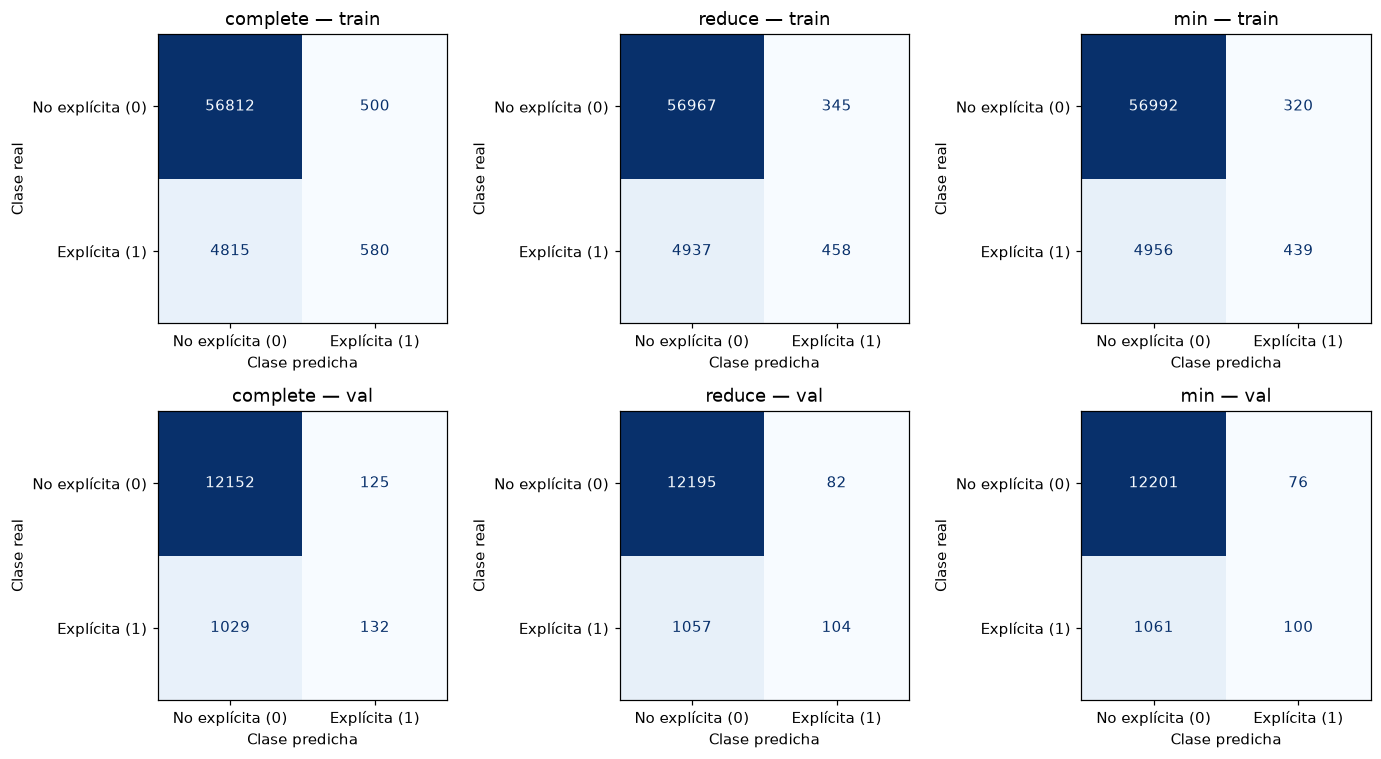

In [15]:
fig, ejes = plt.subplots(2, 3, figsize=(13, 7))
for fila, conjunto in enumerate(['train', 'val']):
    for columna, version in enumerate(configs_y2):
        ConfusionMatrixDisplay(
            confusion_matrix=matrices_y2[(version, conjunto)],
            display_labels=['No explícita (0)', 'Explícita (1)'],
        ).plot(ax=ejes[fila, columna], colorbar=False, cmap='Blues', values_format='d')
        ejes[fila, columna].set_title(f'{version} — {conjunto}')
        ejes[fila, columna].set_xlabel('Clase predicha')
        ejes[fila, columna].set_ylabel('Clase real')
plt.tight_layout()
plt.show()


### 1.B.4 Prueba de las dos mejores versiones logísticas

Se aplican exclusivamente las dos versiones seleccionadas por F1 de validación,
con los desempates ya declarados. Los modelos, columnas y umbral permanecen
fijados. Se reportan métricas y matrices de confusión sin volver a entrenar.

,version,n_vars,accuracy_test,precision_test,recall_test,f1_test,auc_test,f1_val,auc_val,cambio_f1_test_val,cambio_auc_test_val
0,complete,10,0.916059,0.544248,0.107143,0.179039,0.808654,0.186178,0.829415,-0.007138,-0.020761
1,reduce,5,0.915910,0.554217,0.080139,0.140030,0.771338,0.154417,0.789141,-0.014387,-0.017803


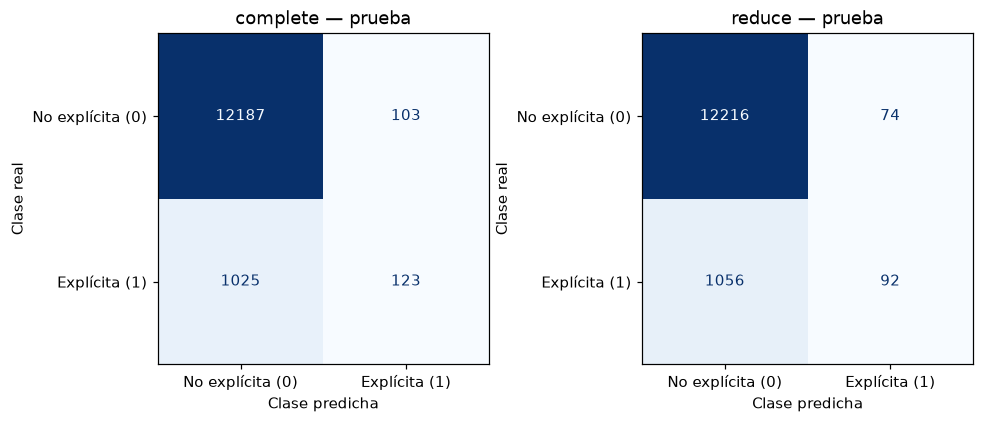

In [16]:
y2_test = df_test[objetivo_y2]
filas_test_y2 = []
matrices_test_y2 = {}
for version in mejores_y2:
    pipe = modelos_y2[version]
    cols = configs_y2[version]
    pred = pipe.predict(df_test[cols])
    proba = probabilidad_positiva(pipe, df_test[cols])
    filas_test_y2.append({
        'version': version, 'n_vars': len(cols),
        **{f'{metrica}_test': valor for metrica, valor in evaluar_clasificacion(
            y2_test, pred, proba
        ).items()},
    })
    matrices_test_y2[version] = confusion_matrix(y2_test, pred, labels=[0, 1])

tabla_test_y2 = pd.DataFrame(filas_test_y2)
comparacion_test_y2 = tabla_test_y2.merge(
    tabla_y2[['version', 'f1_val', 'auc_val']], on='version', validate='one_to_one'
)
comparacion_test_y2['cambio_f1_test_val'] = comparacion_test_y2['f1_test'] - comparacion_test_y2['f1_val']
comparacion_test_y2['cambio_auc_test_val'] = comparacion_test_y2['auc_test'] - comparacion_test_y2['auc_val']
display(comparacion_test_y2.round(6))

fig, ejes = plt.subplots(1, 2, figsize=(9, 4))
for ax, version in zip(ejes, mejores_y2):
    ConfusionMatrixDisplay(
        matrices_test_y2[version], display_labels=['No explícita (0)', 'Explícita (1)']
    ).plot(ax=ax, colorbar=False, cmap='Blues', values_format='d')
    ax.set_title(f'{version} — prueba')
    ax.set_xlabel('Clase predicha')
    ax.set_ylabel('Clase real')
plt.tight_layout()
plt.show()

detalle_prueba_y2 = '; '.join(
    f"{f.version}: F1 validación {f.f1_val:.4f}, prueba {f.f1_test:.4f} "
    f"(cambio {f.cambio_f1_test_val:+.4f}), AUC prueba {f.auc_test:.4f}"
    for f in comparacion_test_y2.itertuples()
)


**Contraste con validación.** complete: F1 validación 0.1862, prueba 0.1790 (cambio -0.0071), AUC prueba 0.8087; reduce: F1 validación 0.1544, prueba 0.1400 (cambio -0.0144), AUC prueba 0.7713. Estos resultados describen el desempeño con pistas reservadas bajo la misma partición aleatoria; no acreditan por sí solos generalización a otros artistas o períodos. La selección permanece basada en validación.

## 1.C — Análisis final

Se integran los resultados de ambas tareas. Las diferencias entre versiones se
interpretan dentro de cada problema: R² y F1 miden objetivos distintos y sus
valores no permiten comparar directamente cuál tarea es más difícil.

In [17]:
pares_correlacion = [
    (a, b, corr_predictoras.loc[a, b])
    for i, a in enumerate(predictorias) for b in predictorias[i + 1:]
]
par_mayor = max(pares_correlacion, key=lambda par: abs(par[2]))
prueba_mejor_y1 = tabla_test_y1.set_index('version').loc[mejor_y1['version']]
prueba_mejor_y2 = tabla_test_y2.set_index('version').loc[mejor_y2['version']]
brechas_f1_y2 = '; '.join(
    f"{f.version}: {f.brecha_f1:+.5f}" for f in tabla_y2.itertuples()
)
comparacion_reduccion = pd.DataFrame({
    'version': list(configs),
    'n_vars': [len(cols) for cols in configs.values()],
    'R2_train': table['R2_train'].to_numpy(),
    'R2_val': table['R2_val'].to_numpy(),
    'brecha_R2': table['brecha_R2'].to_numpy(),
    'F1_train': tabla_y2['f1_train'].to_numpy(),
    'F1_val': tabla_y2['f1_val'].to_numpy(),
    'brecha_F1': tabla_y2['brecha_f1'].to_numpy(),
    'AUC_val': tabla_y2['auc_val'].to_numpy(),
})
display(comparacion_reduccion.round(6))


,version,n_vars,R2_train,R2_val,brecha_R2,F1_train,F1_val,brecha_F1,AUC_val
0,complete,10,0.030716,0.032589,-0.001872,0.179151,0.186178,-0.007027,0.829415
1,reduce,5,0.022696,0.022692,0.000003,0.147790,0.154417,-0.006628,0.789141
2,min,3,0.018605,0.018456,0.000149,0.142671,0.149589,-0.006917,0.778885


### Desempeño y generalización

La mejor regresión explica **3.26%** de la variabilidad de la
popularidad en validación y reduce el RMSE del baseline en **1.64%**.
Las brechas de R² son **complete: -0.00187; reduce: 0.00000; min: 0.00015**. El aporte frente a la referencia debe
valorarse junto con el error que permanece, no solo con la posición en el ranking.

En clasificación, la mejor versión alcanza F1 **0.1862** y recall
**0.1137** en validación, frente a una proporción positiva de
**8.64%**. Las brechas de F1 son **complete: -0.00703; reduce: -0.00663; min: -0.00692**.
Un AUC de **0.8294** puede coexistir con una recuperación limitada
de positivos al umbral 0,5: ordenar probabilidades y tomar decisiones son aspectos
distintos. Accuracy debe contrastarse con el baseline mayoritario.

En prueba, las versiones elegidas como primeras en validación alcanzan R²
**0.0327** y RMSE **20.119**
en regresión, y F1 **0.1790**, recall
**0.1071** y AUC **0.8087**
en clasificación. Se mantiene el diagnóstico de mejora modesta sobre la media
en regresión y baja detección de positivos al umbral fijo en clasificación.

### Influencia de reducir variables

En regresión, las caídas de R² de validación son **+0.00990** para 10→5
y **+0.00424** para 5→3. En clasificación, las caídas de F1 son
**+0.03176** y **+0.00483**. Un cambio negativo significa que
la versión reducida mejora esa métrica. El número de variables por sí solo no
determina la generalización: importan la información eliminada y el criterio de
selección. Los subconjuntos reducidos difieren entre tareas porque se rankean
contra objetivos distintos. Estas comparaciones corresponden a las versiones
evaluadas y no prueban que sean las mejores de todos los subconjuntos posibles.

### Overfitting y underfitting

En esta partición no se observa el patrón clásico de overfitting: las versiones
completas obtienen R² **0.0307** y F1
**0.1792** en entrenamiento, ligeramente inferiores a sus
resultados en validación. En las versiones reducidas tampoco aparece una brecha
grande a favor de entrenamiento. Los resultados de prueba mantienen la baja
capacidad explicativa de popularidad y la baja recuperación de explícitos.
Esto no demuestra ausencia de sobreajuste en otras particiones o poblaciones.

Un desempeño limitado en ambos conjuntos es compatible con underfitting, pero
también con ruido o información predictiva ausente. Los experimentos realizados
no permiten distinguir definitivamente esas causas. La correlación individual
más alta con Y₁ es **-0.1292** para
**instrumentalness**; su cuadrado no es un techo del R² multivariado.
No se puede concluir, a partir de este ranking, que un modelo más flexible sería
incapaz de mejorar.

### Alcance y limitaciones

La popularidad puede depender de difusión, playlists, trayectoria del artista y
contexto temporal, factores no incluidos entre las diez predictoras. Para contenido
explícito faltan las letras y su análisis lingüístico. Son explicaciones posibles
de las limitaciones predictivas; no se ha medido el efecto causal de esos factores.

La mayor correlación absoluta entre predictoras se observa entre **energy**
y **loudness** (**+0.7594**). Esta asociación aconseja cautela al
interpretar coeficientes individuales y al usar rankings univariados; no implica
por sí sola que las predicciones sean inválidas. La regularización de la logística
y el umbral fijo también forman parte de la configuración evaluada.

Se conservaron **9,443** pistas de popularidad cero, evitando
excluir esa parte del objetivo. Aun así, siguen vigentes los filtros sobre tempo,
bailabilidad y duración. La deduplicación impide repetir `track_id`, pero no
garantiza independencia por artista, versiones de una obra ni álbum. La división
aleatoria con una semilla no mide variación entre particiones ni transferencia
temporal. Los resultados de prueba se reportan para las selecciones ya fijadas,
sin utilizarlos para rediseñar los modelos.

## Verificación de cierre

Se comprueban integridad de particiones, anidamiento de variables, ajuste de los
escaladores con entrenamiento y evaluación en prueba de exactamente dos versiones
por tarea. Las comprobaciones no vuelven a entrenar modelos ni generan nuevas
evaluaciones de prueba.

In [18]:
assert sum(len(datos) for datos in particiones.values()) == len(df_clean)
assert all(ids[a].isdisjoint(ids[b]) for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')])
assert np.isfinite(df_clean[columnas_modelado].to_numpy(dtype=float)).all()
assert objetivo_y1 not in predictorias and objetivo_y2 not in predictorias
assert set(configs['complete']) == set(configs_y2['complete']) == set(predictorias)

for configuraciones, modelos in [(configs, models), (configs_y2, modelos_y2)]:
    assert [len(configuraciones[v]) for v in ['complete', 'reduce', 'min']] == [10, 5, 3]
    assert set(configuraciones['min']) <= set(configuraciones['reduce']) <= set(configuraciones['complete'])
    for version, cols in configuraciones.items():
        escalador = modelos[version].named_steps['standardscaler']
        assert escalador.n_samples_seen_ == len(df_train)
        assert list(escalador.feature_names_in_) == cols
        assert np.allclose(escalador.mean_, df_train[cols].mean().to_numpy())
        assert np.allclose(escalador.var_, df_train[cols].var(ddof=0).to_numpy())

assert len(tabla_test_y1) == 2 and tabla_test_y1['version'].tolist() == mejores_y1
assert len(tabla_test_y2) == 2 and tabla_test_y2['version'].tolist() == mejores_y2
assert set(mejores_y1) == set(orden_y1['version'].head(2))
assert set(mejores_y2) == set(orden_y2['version'].head(2))
assert np.isclose(baseline_y1.constant_.item(), y1_train.mean())
for (version, conjunto), matriz in matrices_y2.items():
    assert matriz.sum() == len(particiones[conjunto])
for matriz in matrices_test_y2.values():
    assert matriz.sum() == len(df_test)
assert all(np.isfinite(t.select_dtypes(include='number').to_numpy()).all() for t in [table, tabla_y2, tabla_test_y1, tabla_test_y2])
assert n_ceros_conservados > 0 and seed == 42
print('Verificación completa: particiones, rankings, pipelines y selecciones de prueba coherentes.')


Verificación completa: particiones, rankings, pipelines y selecciones de prueba coherentes.


---
# Parte 2 — Aprendizaje supervisado vs. semisupervisado

**Enunciado:** con un dataset de clasificación (distinto al de la Pregunta 1) de ≥15.000 filas, ≥7 características y etiqueta multiclase, comparar aprendizaje supervisado y semisupervisado con partición 80% / 20% y dos escenarios (10% y 30% del entrenamiento con etiquetas). Se entrenan Regresión Logística y SVM solo con las muestras etiquetadas, luego se pseudoetiqueta con K-Means y DBSCAN (≥2 configuraciones cada uno, buscando llegar al 60% del entrenamiento), se reentrenan los clasificadores (≥3 configuraciones de hiperparámetros por combinación, selección por validación cruzada), se registran todas las configuraciones y se comparan los seis mejores enfoques con ≥3 semillas.

**Contenido:**
- 2.0 Dataset y variables
- 2.1 Preprocesamiento
- 2.2 División de datos y escenarios de etiquetas
- **2.A** Baseline supervisado (Regresión Logística y SVM)
- **2.B** Clustering para pseudoetiquetado (K-Means, DBSCAN, estrategia de asignación)
- **2.C** Entrenamiento semisupervisado y registro de configuraciones
- **2.D** Comparación final de los seis mejores enfoques
- **2.E** Análisis y conclusiones de la Pregunta 2


### 2.0 Dataset y variables

El dataset SDSS17 (Sloan Digital Sky Survey) cumple los requisitos del enunciado: **100.000 filas**, **18 columnas** (17 candidatas a característica) y una etiqueta **multiclase** `class` con tres categorías: GALAXY (59,4%), STAR (21,6%) y QSO (19,0%). Las clases están desbalanceadas, por lo que la métrica principal será **F1 macro** (promedia el F1 de cada clase sin favorecer a la mayoritaria) y se reporta además la accuracy. Las variables utilizadas se justifican en 2.1.


| # | Columna | Descripción | Tipo |
|---|---|---|---|
| 0 | obj_ID | Identificador único del objeto astronómico | Categórica (Id) |
| 1 | alpha | Ángulo de Ascensión Recta (coordenada celeste) | Numérica continua |
| 2 | delta | Ángulo de Declinación (coordenada celeste) | Numérica continua |
| 3 | u | Magnitud fotométrica en banda ultravioleta | Numérica continua |
| 4 | g | Magnitud fotométrica en banda verde | Numérica continua |
| 5 | r | Magnitud fotométrica en banda roja | Numérica continua |
| 6 | i | Magnitud fotométrica en banda infrarroja cercana | Numérica continua |
| 7 | z | Magnitud fotométrica en banda infrarroja | Numérica continua |
| 8 | run_ID | Número de escaneo | Categórica (Id) |
| 9 | rerun_ID | Número de reprocesamiento de imagen | Categórica (Id) |
| 10 | cam_col | Columna de cámara en el escaneo | Categórica (Id) |
| 11 | field_ID | Número de campo del escaneo | Categórica (Id) |
| 12 | spec_obj_ID | Identificador espectroscópico único | Categórica (Id) |
| 13 | class | Clase astronómica: `GALAXY`, `STAR` o `QSO` (Quasar) | Variable Objetivo ($Y$) |
| 14 | redshift | Desplazamiento al rojo espectral | Numérica continua |
| 15 | plate | Identificador de placa de observación | Categórica (Id) |
| 16 | MJD | Fecha Juliana Modificada de la observación | Numérica discreta |
| 17 | fiber_ID | Identificador de fibra óptica | Categórica (Id) |

In [19]:
df_sd.info()
print(df_sd.shape)

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  float64
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 non-null  float64
 13  class        100000 non-null  str    
 14  redshift     100000 non-null  float64
 15  plate        100000 non-null  int64  
 16  MJD          100000 non-null  int64  
 17  fiber_ID     100000 non-null  int64  
dtypes: float64(10), int64(7), str(1)
mem

array([[<Axes: title={'center': 'obj_ID'}>,
        <Axes: title={'center': 'alpha'}>,
        <Axes: title={'center': 'delta'}>, <Axes: title={'center': 'u'}>],
       [<Axes: title={'center': 'g'}>, <Axes: title={'center': 'r'}>,
        <Axes: title={'center': 'i'}>, <Axes: title={'center': 'z'}>],
       [<Axes: title={'center': 'run_ID'}>,
        <Axes: title={'center': 'rerun_ID'}>,
        <Axes: title={'center': 'cam_col'}>,
        <Axes: title={'center': 'field_ID'}>],
       [<Axes: title={'center': 'spec_obj_ID'}>,
        <Axes: title={'center': 'redshift'}>,
        <Axes: title={'center': 'plate'}>,
        <Axes: title={'center': 'MJD'}>],
       [<Axes: title={'center': 'fiber_ID'}>, <Axes: >, <Axes: >,
        <Axes: >]], dtype=object)

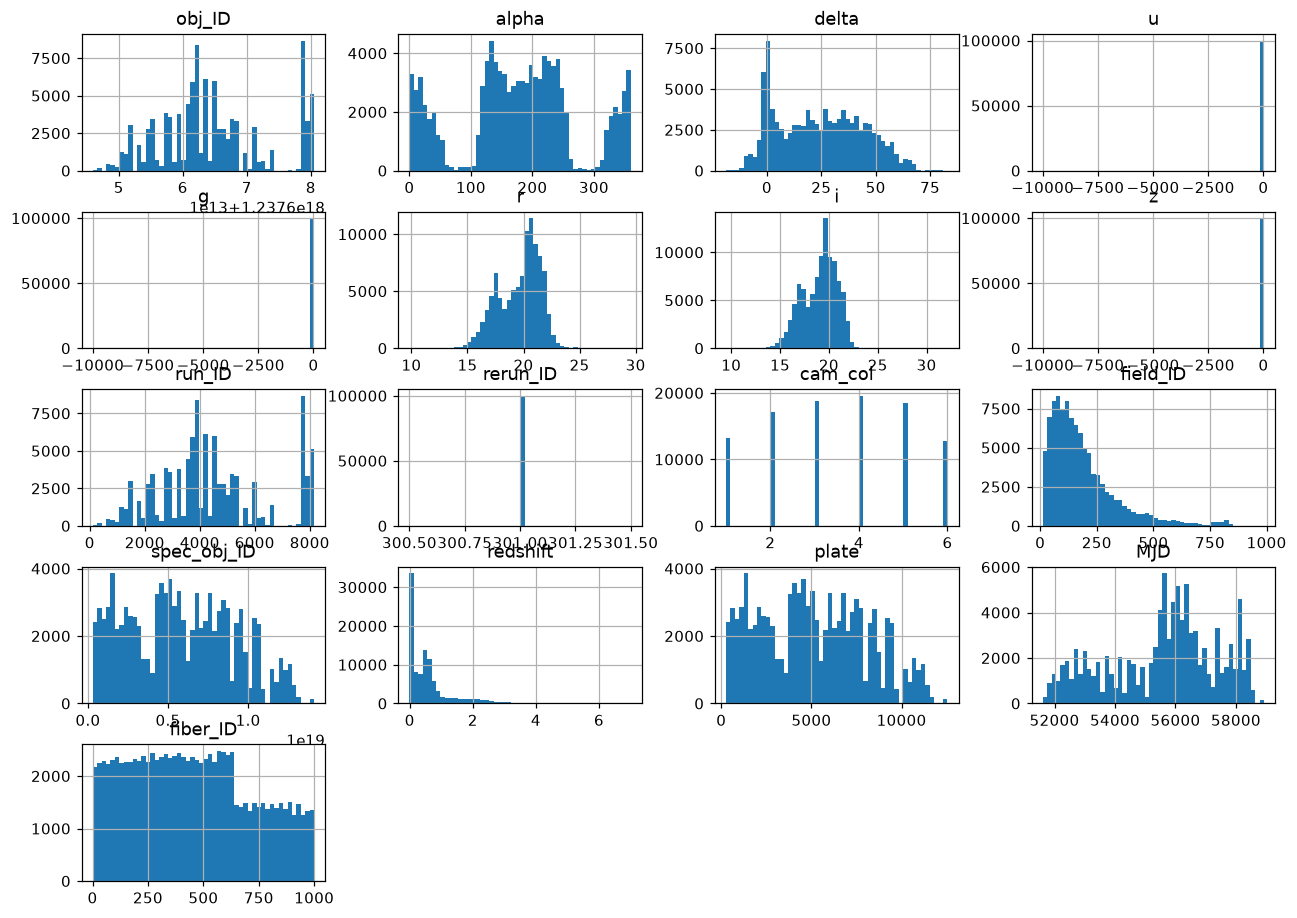

In [20]:
df_sd.hist(bins=50, figsize=(14,10))


### 2.1 Preprocesamiento

_Selección de características, limpieza, escalamiento, codificación de la etiqueta._

In [21]:
print(df_sd['class'].unique())
print(df_sd['class'].value_counts())
print(df_sd['class'].value_counts(normalize=True))

caracteristicas =[
    'alpha',
    'u',  
    'g',
    'r',
    'i',
    'z',
    'redshift'
]
df_sd[caracteristicas].describe()


<StringArray>
['GALAXY', 'QSO', 'STAR']
Length: 3, dtype: str
class
GALAXY    59445
STAR      21594
QSO       18961
Name: count, dtype: int64
class
GALAXY    0.59445
STAR      0.21594
QSO       0.18961
Name: proportion, dtype: float64


,alpha,u,g,r,i,z,redshift
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,177.629117,21.980468,20.531387,19.645762,19.084854,18.668810,0.576661
std,96.502241,31.769291,31.750292,1.854760,1.757895,31.728152,0.730707
min,0.005528,-9999.000000,-9999.000000,9.822070,9.469903,-9999.000000,-0.009971
25%,127.518222,20.352353,18.965230,18.135828,17.732285,17.460677,0.054517
50%,180.900700,22.179135,21.099835,20.125290,19.405145,19.004595,0.424173
75%,233.895005,23.687440,22.123767,21.044785,20.396495,19.921120,0.704154
max,359.999810,32.781390,31.602240,29.571860,32.141470,29.383740,7.011245


**Características utilizadas (7):** `alpha`, `u`, `g`, `r`, `i`, `z` y `redshift`.

- **Magnitudes `u, g, r, i, z`:** miden el brillo del objeto en cinco bandas del espectro. Cada tipo de objeto emite distinto en cada banda (estrellas, galaxias y cuásares tienen colores característicos), así que describen *qué es* el objeto.
- **`redshift`:** es la variable más discriminante: las estrellas tienen redshift ≈ 0 (media −0,00), las galaxias ≈ 0,42 y los cuásares ≈ 1,72, porque están a distancias muy distintas.
- **`alpha`:** se conserva como una de las dos coordenadas celestes. Se deja solo una porque `alpha` y `delta` describen *dónde* está el objeto en el cielo y no *qué* es; no deberían aportar información de la clase y mantener ambas duplicaría ese ruido. Se escogió `alpha` y se descartó `delta` (su correlación es de solo 0,14, así que no se descarta por redundancia sino por parsimonia: se conserva una sola coordenada y aun así se cumplen las ≥7 características).

**Variables descartadas:** `obj_ID`, `run_ID`, `rerun_ID`, `cam_col`, `field_ID`, `spec_obj_ID`, `plate`, `MJD` y `fiber_ID` son **identificadores o metadatos de la observación** (qué escaneo, qué cámara, qué placa, qué fecha). Son números sin significado físico: un modelo lineal los interpretaría como cantidades ordenadas y podría aprender artefactos del proceso de medición en vez de propiedades del objeto. `delta` se descartó por el argumento de «dónde está vs. qué es» ya explicado.

**Limpieza (valor centinela):** `u`, `g` y `z` tienen un mínimo de −9999, que no es una magnitud real sino un **código de dato faltante**. Como las magnitudes reales son > 9, se usa el umbral `>= -100` para detectarlo. Solo **1 fila** lo contiene (índice 79543, clase **STAR**), por lo que se elimina (100.000 → 99.999 filas) sin alterar de forma relevante la distribución de clases. Dejarla habría distorsionado el escalamiento, pues un valor de −9999 desplaza fuertemente la media y la desviación estándar.

**Escalamiento y etiqueta:** el escalamiento (`StandardScaler`) se incluye *dentro* de cada pipeline (o se ajusta solo con el entrenamiento, en el caso del clustering) para que `X_test` nunca influya en la media ni en la desviación. La etiqueta `class` se deja como texto: scikit-learn maneja internamente las tres clases (la regresión logística usa multinomial y `LinearSVC` usa uno-contra-resto).

In [22]:
for col in df_sd[caracteristicas]:
    print(col, df_sd[col].min(), df_sd[col].max())


mask = (df_sd[caracteristicas] >= -100).all(axis=1)


clean = df_sd[mask].copy()
print(len(df_sd), '->', len(clean) )


for col in clean[caracteristicas]:
    print(col, clean[col].min(), clean[col].max())


y = clean['class']
X = clean[caracteristicas]


alpha 0.0055278279239701 359.999809770956
u -9999.0 32.78139
g -9999.0 31.60224
r 9.82207 29.57186
i 9.469903 32.14147
z -9999.0 29.38374
redshift -0.009970667 7.011245
100000 -> 99999
alpha 0.0055278279239701 359.999809770956
u 10.99623 32.78139
g 10.4982 31.60224
r 9.82207 29.57186
i 9.469903 32.14147
z 9.612333 29.38374
redshift -0.009970667 7.011245


### 2.2 División de datos (80% entrenamiento / 20% testing) y escenarios de etiquetas

Se separa el 80% para entrenamiento (79.999 filas) y el 20% para testing (20.000 filas) con `stratify=y` y `random_state=42`, de modo que ambas partes mantienen la proporción de clases. El conjunto de testing **no se toca** hasta la evaluación final.

Dentro del entrenamiento se simulan dos escenarios en que solo una fracción tiene etiqueta conocida: **A_10** (10%, ≈8.000 muestras) y **B_30** (30%, ≈24.000 muestras). La selección también es estratificada y se repite con **tres semillas (42, 25 y 666)**, de modo que cada escenario tiene tres subconjuntos etiquetados distintos. El resto de las muestras se trata como *sin etiqueta* (sus etiquetas reales solo se usan después para medir la calidad de las pseudoetiquetas).


En  `train_test_split`, el primer valor que retorna es la parte *train* y el segundo valor es el *test*

In [23]:
split_test = 0.20
split_train = 0.80

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=split_train, stratify=y, random_state=42)

print("Train:", len(y_train))
print("Test: ", len(y_test))
print("Suma correcta:", (len(y_train) + len(y_test)) == len(y))

print("\nProporción en Train:\n", y_train.value_counts(normalize=True))
print("\nProporción en Test:\n", y_test.value_counts(normalize=True))

print("Posiciones:", np.arange(len(y_train)))


Train: 79999
Test:  20000
Suma correcta: True

Proporción en Train:
 class
GALAXY    0.594457
STAR      0.215928
QSO       0.189615
Name: proportion, dtype: float64

Proporción en Test:
 class
GALAXY    0.59445
STAR      0.21595
QSO       0.18960
Name: proportion, dtype: float64
Posiciones: [    0     1     2 ... 79996 79997 79998]


In [24]:
seed = 42
SEMILLAS = [42, 25, 666]
def crear_escenarios(y_train, fraccion ,seed):
    posiciones =  np.arange(len(y_train))
    know_labels, unknown_labels = train_test_split(posiciones, train_size=fraccion, stratify=y_train, random_state=seed)
    
    return know_labels, unknown_labels


In [25]:
escenarios = {
    "A_10": 0.10, # escenario con el 10% de etiquetas conocidas
    "B_30": 0.30, # escenario con el 30% de etiquetas conocidas
}
SEMILLAS = [42, 25, 666]

resultado_escenarios = {}

for escenario, fraccion in escenarios.items():
    print(f"Escenario {escenario}: {fraccion*100}% de etiquetas conocidas")
    for semilla in SEMILLAS:    
        known_label, unknown_label = crear_escenarios(y_train, fraccion, semilla)
        resultado_escenarios[(escenario, semilla)] = {
            "known": known_label,
            "unknown": unknown_label
        }
        print(f"Nombre {escenario}: {len(known_label)} etiquetas conocidas, {len(unknown_label)} etiquetas desconocidas")

        print(f"Clases presentes: {np.unique(y_train.iloc[known_label])}")


print(len(resultado_escenarios))                         # debe dar 6
print(resultado_escenarios[("A_10", 42)]["known"][:5])
print(resultado_escenarios[("A_10", 25)]["known"][:5])   # debe ser distinto al anterior


Escenario A_10: 10.0% de etiquetas conocidas
Nombre A_10: 7999 etiquetas conocidas, 72000 etiquetas desconocidas
Clases presentes: ['GALAXY' 'QSO' 'STAR']
Nombre A_10: 7999 etiquetas conocidas, 72000 etiquetas desconocidas
Clases presentes: ['GALAXY' 'QSO' 'STAR']
Nombre A_10: 7999 etiquetas conocidas, 72000 etiquetas desconocidas
Clases presentes: ['GALAXY' 'QSO' 'STAR']
Escenario B_30: 30.0% de etiquetas conocidas
Nombre B_30: 23999 etiquetas conocidas, 56000 etiquetas desconocidas
Clases presentes: ['GALAXY' 'QSO' 'STAR']
Nombre B_30: 23999 etiquetas conocidas, 56000 etiquetas desconocidas
Clases presentes: ['GALAXY' 'QSO' 'STAR']
Nombre B_30: 23999 etiquetas conocidas, 56000 etiquetas desconocidas
Clases presentes: ['GALAXY' 'QSO' 'STAR']
6
[52499 52236 32890 17359 15814]
[74525 74427 24550 76523 11141]


## 2.A — Baseline supervisado (solo muestras etiquetadas)

### 2.A.1 Regresión Logística — hiperparámetros y justificación (≥3 configuraciones)

Se entrena una regresión logística **solo con las muestras etiquetadas** de cada escenario. Es un modelo lineal que estima la probabilidad de cada clase con softmax (multinomial) y se entrena minimizando la **entropía cruzada (log-loss)** más una penalización **L2**.

**Hiperparámetro:** `C`, el inverso de la fuerza de regularización. Se prueban tres valores en escala logarítmica que cubren el espectro completo:
- `C = 0,01`: regularización fuerte, modelo muy restringido (riesgo de subajuste).
- `C = 1,0`: valor por defecto, equilibrio intermedio.
- `C = 100`: regularización débil, el modelo se ajusta casi libremente a los datos.

**Selección:** validación cruzada de 5 particiones sobre las muestras etiquetadas (semilla 42), con **F1 macro** como criterio, sin usar etiquetas desconocidas ni testing. La mejor `C` se reentrena con cada una de las tres semillas y se evalúa en testing (F1 macro y accuracy). En ambos escenarios gana `C = 100` (F1 macro CV ≈ 0,9535 en A_10 y ≈ 0,9536 en B_30). Además `max_iter=1000` para asegurar convergencia, y el `StandardScaler` dentro del pipeline evita fuga de información entre particiones.

In [26]:
resultados = []


configs = [
    0.01,
    1.0,
    100.0
]

for escenario, fraccion in escenarios.items():
    id_known= resultado_escenarios[(escenario, 42)]['known']

    # Se seleccionan solo las caracteristicas etiquetadas
    X_base = X_train.iloc[id_known]
    y_base = y_train.iloc[id_known]

    mejor_puntaje = 0.0
    mejor_config = 0.0

    for config in configs:
        pipe = make_pipeline(StandardScaler(), LogisticRegression(C=config, max_iter=1000))

        #Validacion cruzada solo sobre las etiquetas conocidas
        scores = cross_val_score(pipe, X_base, y_base, cv=5, scoring='f1_macro')
        promedio = scores.mean()

        resultados.append({
            'escenario'   : escenario,                    # A_10 o B_30
            'semilla'     : 42,                        # 42, 7 o 123
            'enfoque'     : 'logistica_supervisada',   
            'config'      : config,                   # la configuración probada
            'etapa'       : 'cv',                      # 'cv' o 'test'
            'n_etiquetas' : len(id_known),                      # con cuántas entrenó
            'f1_macro'    : promedio,                       # la métrica principal
            'accuracy'    : None,
            'precision_pseudo' : None,   
            'cobertura'        : None   
        })
        if promedio > mejor_puntaje:
            mejor_puntaje = promedio
            mejor_config = config


    for semilla in SEMILLAS:
        id_known = resultado_escenarios[(escenario, semilla)]["known"]

        X_base = X_train.iloc[id_known]
        y_base = y_train.iloc[id_known]

        pipe_final = make_pipeline(StandardScaler(), LogisticRegression(C=mejor_config, max_iter=1000))
        pipe_final.fit(X_base, y_base)

        # Conjunto de prueba 
        prediccion_test = pipe_final.predict(X_test)
        resultados.append({
            'escenario'   : escenario,                    
            'semilla'     : semilla,                        
            'enfoque'     : 'logistica_supervisada',
            'config'      : mejor_config,                   
            'etapa'       : 'test',                      
            'n_etiquetas' : len(id_known),                      
            'f1_macro'    : f1_score(y_test, prediccion_test, average='macro'),                    
            'accuracy'    : accuracy_score(y_test, prediccion_test),
            'precision_pseudo' : None,
            'cobertura'        : None
        })

display(pd.DataFrame((resultados)))
        

,escenario,semilla,enfoque,config,etapa,n_etiquetas,f1_macro,accuracy,precision_pseudo,cobertura
0,A_10,42,logistica_supervisada,0.01,cv,7999,0.831770,NaN,None,None
1,A_10,42,logistica_supervisada,1.00,cv,7999,0.945077,NaN,None,None
2,A_10,42,logistica_supervisada,100.00,cv,7999,0.953500,NaN,None,None
3,A_10,42,logistica_supervisada,100.00,test,7999,0.954609,0.96080,None,None
4,A_10,25,logistica_supervisada,100.00,test,7999,0.954489,0.96065,None,None
5,A_10,666,logistica_supervisada,100.00,test,7999,0.955158,0.96120,None,None
6,B_30,42,logistica_supervisada,0.01,cv,23999,0.877049,NaN,None,None
7,B_30,42,logistica_supervisada,1.00,cv,23999,0.944833,NaN,None,None
8,B_30,42,logistica_supervisada,100.00,cv,23999,0.953607,NaN,None,None
9,B_30,42,logistica_supervisada,100.00,test,23999,0.956603,0.96265,None,None


### 2.A.2 SVM — hiperparámetros y justificación (≥3 configuraciones)

Se usa `LinearSVC`, una SVM de **kernel lineal**, elegida en vez de `SVC` con kernel RBF porque con 8.000–24.000 muestras y validación cruzada el kernel RBF sería muy costoso (complejidad cercana a cuadrática en el número de muestras), mientras que la versión lineal escala bien. Se entrena con la **pérdida hinge al cuadrado** más penalización **L2** y usa la estrategia uno-contra-resto para las tres clases.

**Hiperparámetro:** `C` (penalización por errores de clasificación; es el inverso de la regularización). Se prueban `0,01`, `1,0` y `100`, con la misma lógica que en la regresión logística: de margen muy amplio y permisivo a margen estricto que penaliza fuertemente cada error. La selección se hace por validación cruzada de 5 particiones con F1 macro, sin usar testing, y el mejor valor se evalúa con las tres semillas. Gana `C = 100` en ambos escenarios (F1 macro CV ≈ 0,936 en A_10 y ≈ 0,934 en B_30), algo por debajo de la regresión logística.

In [27]:

configs = [
    0.01,
    1.0,
    100.0
]

for escenario, fraccion in escenarios.items():
    id_known= resultado_escenarios[(escenario, 42)]['known']

    # Se seleccionan solo las caracteristicas etiquetadas
    X_base = X_train.iloc[id_known]
    y_base = y_train.iloc[id_known]

    mejor_puntaje = 0.0
    mejor_config = 0.0

    for config in configs:
        pipe = make_pipeline(StandardScaler(), LinearSVC(C=config, max_iter=1000))

        #Validacion cruzada solo sobre las etiquetas conocidas
        scores = cross_val_score(pipe, X_base, y_base, cv=5, scoring='f1_macro')
        promedio = scores.mean()

        resultados.append({
            'escenario'   : escenario,                    # A_10 o B_30
            'semilla'     : 42,                        # 42, 25 o 666
            'enfoque'     : 'svm_supervisada',   
            'config'      : config,                   # la configuración probada
            'etapa'       : 'cv',                      # 'cv' o 'test'
            'n_etiquetas' : len(id_known),                      # con cuántas entrenó
            'f1_macro'    : promedio,                       # la métrica principal
            'accuracy'    : None,
            'precision_pseudo' : None,   
            'cobertura'        : None   
        })
        if promedio > mejor_puntaje:
            mejor_puntaje = promedio
            mejor_config = config


    for semilla in SEMILLAS:
        id_known = resultado_escenarios[(escenario, semilla)]["known"]

        X_base = X_train.iloc[id_known]
        y_base = y_train.iloc[id_known]

        pipe_final = make_pipeline(StandardScaler(), LinearSVC(C=mejor_config, max_iter=1000))
        pipe_final.fit(X_base, y_base)

        # Conjunto de prueba 
        prediccion_test = pipe_final.predict(X_test)
        resultados.append({
            'escenario'   : escenario,                    
            'semilla'     : semilla,                        
            'enfoque'     : 'svm_supervisada',
            'config'      : mejor_config,                   
            'etapa'       : 'test',                      
            'n_etiquetas' : len(id_known),                      
            'f1_macro'    : f1_score(y_test, prediccion_test, average='macro'),                    
            'accuracy'    : accuracy_score(y_test, prediccion_test),
            'precision_pseudo' : None,
            'cobertura'        : None
        })

display(pd.DataFrame((resultados)))
        

,escenario,semilla,enfoque,config,etapa,n_etiquetas,f1_macro,accuracy,precision_pseudo,cobertura
0,A_10,42,logistica_supervisada,0.01,cv,7999,0.831770,NaN,None,None
1,A_10,42,logistica_supervisada,1.00,cv,7999,0.945077,NaN,None,None
2,A_10,42,logistica_supervisada,100.00,cv,7999,0.953500,NaN,None,None
3,A_10,42,logistica_supervisada,100.00,test,7999,0.954609,0.96080,None,None
4,A_10,25,logistica_supervisada,100.00,test,7999,0.954489,0.96065,None,None
5,A_10,666,logistica_supervisada,100.00,test,7999,0.955158,0.96120,None,None
6,B_30,42,logistica_supervisada,0.01,cv,23999,0.877049,NaN,None,None
7,B_30,42,logistica_supervisada,1.00,cv,23999,0.944833,NaN,None,None
8,B_30,42,logistica_supervisada,100.00,cv,23999,0.953607,NaN,None,None
9,B_30,42,logistica_supervisada,100.00,test,23999,0.956603,0.96265,None,None


## 2.B — Clustering para pseudoetiquetado

### 2.B.1 K-Means (≥2 configuraciones)

Se aplica K-Means sobre el entrenamiento **escalado** (`StandardScaler` ajustado solo con `X_train`), sin usar etiquetas. Se prueban dos configuraciones, **k = 3** (el número real de clases) y **k = 6** (sobresegmentación), con `n_init=10` y `random_state=42`. Se guarda también la distancia de cada punto a su centroide, que luego sirve para ordenar la confianza.

La idea de k = 6 es que los clusters más pequeños sean más *puros*: con k = 3 un cluster mezcla galaxias, cuásares y estrellas parcialmente solapados; con más clusters cada uno cubre una región más homogénea. Las métricas de 2.B.3 confirman esto: k = 6 produce pseudoetiquetas con ~99,3% de acierto frente a ~94% con k = 3.

In [28]:


grupos = {}
distancias = {}


escalador  = StandardScaler().fit(X_train)
X_train_esc = escalador.transform(X_train)

for k in [3, 6]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    grupos[f"km_{k}"] = km.fit_predict(X_train_esc)   
    distancias[f"km_{k}"] = km.transform(X_train_esc).min(axis=1)

print(np.bincount(grupos["km_3"]))


[12680 25620 41699]


### 2.B.2 DBSCAN (≥2 configuraciones)

DBSCAN no requiere fijar el número de clusters y detecta ruido (etiqueta −1). Se prueban dos configuraciones con `min_samples=10` y **eps = 0,3** y **eps = 0,6** (sobre datos escalados). Como DBSCAN no tiene centroides, la «distancia» se deja en 0 y todos los candidatos válidos quedan al mismo nivel.

Resultado: `eps = 0,3` forma 29 clusters y deja un 14,8% de puntos como ruido; `eps = 0,6` es demasiado permisivo y colapsa todo en solo 2 clusters (1,7% de ruido), mezclando clases. Por eso se usa `eps = 0,3` como mejor DBSCAN.

In [29]:
for eps in [0.3, 0.6]:
    etiquetas = DBSCAN(eps=eps, min_samples=10).fit_predict(X_train_esc)
    grupos[f"db_{eps}"] = etiquetas
    distancias[f"db_{eps}"] = np.zeros(len(etiquetas))
    

### 2.B.3 Estrategia de asignación de pseudoetiquetas

**Estrategia.** Para cada cluster se mide, usando *solo las muestras etiquetadas*, la clase mayoritaria y su **pureza** (fracción de la clase mayoritaria). Luego:
1. Cada muestra sin etiqueta hereda la clase mayoritaria de su cluster, pero **solo si la pureza del cluster es ≥ 0,9**; los clusters mixtos y el ruido de DBSCAN no se pseudoetiquetan.
2. Los candidatos se ordenan por cercanía a su centroide (en K-Means) y se toman hasta alcanzar el **60%** del entrenamiento entre reales y estimadas.

**Configuraciones elegidas:** `km_6` y `db_0.3` (tablas siguientes). `km_3` asigna más muestras pero con menos acierto (94,1% vs 99,3%), y `db_0.6` casi no produce pseudoetiquetas utilizables. Se prefirió la calidad de la pseudoetiqueta a la cantidad, porque un error de etiquetado se propaga al clasificador.

**Limitación: no se alcanza el 60%.** Con el umbral de pureza 0,9 la cobertura queda en torno a **21% (K-Means) y 11% (DBSCAN) en A_10**, y **39% y 31% en B_30**. Los clusters que superan la pureza exigida son pocos (las clases GALAXY y QSO se solapan en el espacio de magnitudes y los clusters mixtos se descartan), y DBSCAN además deja ~15% de los datos como ruido. Bajar el umbral permitiría más cobertura, pero a costa de introducir más pseudoetiquetas erróneas.

In [30]:
def pseudoetiquetar(clave, known, unknown, umbral=0.9):
    g = grupos[clave]
    tabla = pd.crosstab(g[known], y_train.iloc[known].values)
    tabla = tabla.drop(-1, errors='ignore')
    clase_c = tabla.idxmax(axis=1)
    pureza_c = tabla.max(axis=1) / tabla.sum(axis=1)
    
    pureza_u = pd.Series(g[unknown]).map(pureza_c).fillna(0).values
    candidatos = unknown[pureza_u >= umbral]
    candidatos = candidatos[np.argsort(distancias[clave][candidatos])]
    meta = int(0.60 * len(y_train)) - len(known)  
    elegidos = candidatos[:meta]
    pseudo_label = pd.Series(g[elegidos]).map(clase_c).values

    return elegidos, pseudo_label

mejor_km = "km_6"
mejor_db = "db_0.3"


In [31]:
# Calidad de cada configuracion de clustering (semilla 42): pureza de la pseudoetiqueta y cobertura
filas = []
for escenario in escenarios:
    known = resultado_escenarios[(escenario, 42)]["known"]
    unknown = resultado_escenarios[(escenario, 42)]["unknown"]
    for clave in grupos:
        elegidos, pseudo = pseudoetiquetar(clave, known, unknown)
        filas.append({
            "escenario": escenario, "clustering": clave,
            "n_clusters": len(set(grupos[clave]) - {-1}),
            "ruido_%": round((grupos[clave] == -1).mean() * 100, 2),
            "pseudo_asignadas": len(elegidos),
            "cobertura": round((len(known) + len(elegidos)) / len(y_train), 3),
            "precision_pseudo": round((pseudo == y_train.iloc[elegidos].values).mean(), 4) if len(elegidos) else np.nan,
        })
display(pd.DataFrame(filas))

,escenario,clustering,n_clusters,ruido_%,pseudo_asignadas,cobertura,precision_pseudo
0,A_10,km_3,3,0.00,11413,0.243,0.9406
1,A_10,km_6,6,0.00,8811,0.210,0.9926
2,A_10,db_0.3,29,14.78,473,0.106,0.9556
3,A_10,db_0.6,2,1.72,26,0.100,0.8462
4,B_30,km_3,3,0.00,8885,0.411,0.9409
5,B_30,km_6,6,0.00,6862,0.386,0.9937
6,B_30,db_0.3,29,14.78,480,0.306,0.9604
7,B_30,db_0.6,2,1.72,0,0.300,NaN


## 2.C — Entrenamiento con pseudoetiquetas (semisupervisado)

### 2.C.1 Regresión Logística + pseudoetiquetas (K-Means / DBSCAN)

Se reentrena la regresión logística con las muestras **reales + pseudoetiquetadas** (ambos métodos de clustering, ambos escenarios). Se prueban las mismas tres configuraciones `C ∈ {0,01; 1; 100}`; la selección es por validación cruzada de 5 particiones (F1 macro, semilla 42) sobre el conjunto aumentado, y el modelo elegido se evalúa en testing, que siempre contiene etiquetas reales, con las tres semillas. La función de pérdida es la misma entropía cruzada con L2 del baseline, de modo que la única diferencia es el conjunto de entrenamiento. Se registra además la **precisión de las pseudoetiquetas** (aciertos respecto de la etiqueta real oculta) y la **cobertura** (fracción del entrenamiento con etiqueta, real o estimada).

La validación cruzada puntúa más alto (≈ 0,97) que testing (≈ 0,955) porque parte de los datos de validación llevan pseudoetiquetas generadas por el mismo clustering, que son más «fáciles» y coherentes que las etiquetas reales; por eso solo testing es comparable entre enfoques.

In [32]:
def entrenar_semisupervisado(nombre_modelo, Modelo, configs=(0.01, 1.0, 100.0)):
    """Pseudoetiqueta con K-Means y DBSCAN, elige C por CV (semilla 42) y evalua en test con 3 semillas."""
    for metodo, clave in [("kmeans", mejor_km), ("dbscan", mejor_db)]:
        enfoque = f"{nombre_modelo}_{metodo}"
        for escenario in escenarios:

            def armar_entrenamiento(semilla):
                known = resultado_escenarios[(escenario, semilla)]["known"]
                unknown = resultado_escenarios[(escenario, semilla)]["unknown"]
                elegidos, pseudo = pseudoetiquetar(clave, known, unknown)
                X_aug = np.concatenate([X_train.iloc[known].values, X_train.iloc[elegidos].values])
                y_aug = np.concatenate([y_train.iloc[known].values, pseudo])
                prec = (pseudo == y_train.iloc[elegidos].values).mean()   # solo para evaluar la calidad
                cob = (len(known) + len(elegidos)) / len(y_train)
                return X_aug, y_aug, prec, cob, len(known)

            # Seleccion de C por validacion cruzada (semilla 42), sin usar testing
            X_aug, y_aug, prec, cob, n_known = armar_entrenamiento(42)
            mejor_puntaje, mejor_config = -1.0, None
            for config in configs:
                pipe = make_pipeline(StandardScaler(), Modelo(C=config, max_iter=1000))
                promedio = cross_val_score(pipe, X_aug, y_aug, cv=5, scoring='f1_macro').mean()
                resultados.append({
                    'escenario': escenario, 'semilla': 42, 'enfoque': enfoque, 'config': config,
                    'etapa': 'cv', 'n_etiquetas': n_known, 'f1_macro': promedio, 'accuracy': None,
                    'precision_pseudo': prec, 'cobertura': cob
                })
                if promedio > mejor_puntaje:
                    mejor_puntaje, mejor_config = promedio, config

            # Evaluacion final en test con las 3 semillas
            for semilla in SEMILLAS:
                X_aug, y_aug, prec, cob, n_known = armar_entrenamiento(semilla)
                pipe_final = make_pipeline(StandardScaler(), Modelo(C=mejor_config, max_iter=1000))
                pipe_final.fit(X_aug, y_aug)
                pred = pipe_final.predict(X_test)
                resultados.append({
                    'escenario': escenario, 'semilla': semilla, 'enfoque': enfoque, 'config': mejor_config,
                    'etapa': 'test', 'n_etiquetas': n_known,
                    'f1_macro': f1_score(y_test, pred, average='macro'),
                    'accuracy': accuracy_score(y_test, pred),
                    'precision_pseudo': prec, 'cobertura': cob
                })

entrenar_semisupervisado("logistica", LogisticRegression)
df_res = pd.DataFrame(resultados)
display(df_res[df_res["enfoque"].str.startswith("logistica_") & ~df_res["enfoque"].str.contains("supervisada")])

/Users/andres/Desktop/tarea2IA/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/Users/andres/Desktop/tarea2IA/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/Users/andres/Desktop/tarea2IA/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/Users/andres/Desktop/tarea2IA/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/Users/andres/Desktop/tarea2IA/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  

,escenario,semilla,enfoque,config,etapa,n_etiquetas,f1_macro,accuracy,precision_pseudo,cobertura
24,A_10,42,logistica_kmeans,0.01,cv,7999,0.847582,NaN,0.992623,0.210128
25,A_10,42,logistica_kmeans,1.00,cv,7999,0.963491,NaN,0.992623,0.210128
26,A_10,42,logistica_kmeans,100.00,cv,7999,0.972612,NaN,0.992623,0.210128
27,A_10,42,logistica_kmeans,100.00,test,7999,0.955183,0.96100,0.992623,0.210128
28,A_10,25,logistica_kmeans,100.00,test,7999,0.954450,0.96025,0.992279,0.210078
29,A_10,666,logistica_kmeans,100.00,test,7999,0.954479,0.96035,0.992851,0.210153
30,B_30,42,logistica_kmeans,0.01,cv,23999,0.867682,NaN,0.993734,0.385767
31,B_30,42,logistica_kmeans,1.00,cv,23999,0.959711,NaN,0.993734,0.385767
32,B_30,42,logistica_kmeans,100.00,cv,23999,0.969024,NaN,0.993734,0.385767
33,B_30,42,logistica_kmeans,100.00,test,23999,0.956627,0.96250,0.993734,0.385767


### 2.C.2 SVM + pseudoetiquetas (K-Means / DBSCAN)

Mismo procedimiento con `LinearSVC` (hinge cuadrada + L2), `C ∈ {0,01; 1; 100}`, K-Means y DBSCAN, ambos escenarios y tres semillas. Los resultados de cada corrida (CV y test) se muestran bajo la celda.

In [33]:
entrenar_semisupervisado("svm", LinearSVC)
df_res = pd.DataFrame(resultados)
display(df_res[df_res["enfoque"].str.startswith("svm_") & ~df_res["enfoque"].str.contains("supervisada")])

/Users/andres/Desktop/tarea2IA/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/Users/andres/Desktop/tarea2IA/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/Users/andres/Desktop/tarea2IA/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/Users/andres/Desktop/tarea2IA/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/Users/andres/Desktop/tarea2IA/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  

,escenario,semilla,enfoque,config,etapa,n_etiquetas,f1_macro,accuracy,precision_pseudo,cobertura
48,A_10,42,svm_kmeans,0.01,cv,7999,0.842809,NaN,0.992623,0.210128
49,A_10,42,svm_kmeans,1.00,cv,7999,0.927625,NaN,0.992623,0.210128
50,A_10,42,svm_kmeans,100.00,cv,7999,0.949544,NaN,0.992623,0.210128
51,A_10,42,svm_kmeans,100.00,test,7999,0.922179,0.93005,0.992623,0.210128
52,A_10,25,svm_kmeans,100.00,test,7999,0.927186,0.93440,0.992279,0.210078
53,A_10,666,svm_kmeans,100.00,test,7999,0.922070,0.92995,0.992851,0.210153
54,B_30,42,svm_kmeans,0.01,cv,23999,0.863901,NaN,0.993734,0.385767
55,B_30,42,svm_kmeans,1.00,cv,23999,0.935091,NaN,0.993734,0.385767
56,B_30,42,svm_kmeans,100.00,cv,23999,0.946160,NaN,0.993734,0.385767
57,B_30,42,svm_kmeans,100.00,test,23999,0.929080,0.93640,0.993734,0.385767


### 2.C.3 Registro de todas las configuraciones evaluadas

La tabla reúne **todas las configuraciones evaluadas**: modelo, método de pseudoetiquetado, escenario, semilla, etapa (`cv` o `test`), valor de `C`, función de pérdida, número de etiquetas reales, F1 macro, accuracy, precisión de las pseudoetiquetas y cobertura. Funciones de pérdida: **entropía cruzada (log-loss) con L2** para la regresión logística y **hinge cuadrada con L2** para `LinearSVC`. Primero se listan las filas de validación cruzada (selección de `C`) y luego las de testing.

In [34]:
df_res = pd.DataFrame(resultados)
df_res["funcion_perdida"] = df_res["enfoque"].map(
    lambda e: "Entropia cruzada (log-loss), L2" if e.startswith("logistica") else "Hinge cuadrada (LinearSVC), L2")
df_res["modelo"] = df_res["enfoque"].str.split("_").str[0]
df_res["metodo"] = df_res["enfoque"].str.split("_").str[1].replace({"supervisada": "ninguno"})

registro = df_res[["modelo", "metodo", "enfoque", "escenario", "semilla", "etapa", "config",
                   "funcion_perdida", "n_etiquetas", "f1_macro", "accuracy",
                   "precision_pseudo", "cobertura"]].rename(columns={"config": "C"})
print("Total de configuraciones/corridas registradas:", len(registro))
display(registro[registro["etapa"] == "cv"].sort_values(["enfoque", "escenario", "C"]).reset_index(drop=True))
display(registro[registro["etapa"] == "test"].sort_values(["enfoque", "escenario", "semilla"]).reset_index(drop=True))

Total de configuraciones/corridas registradas: 72


,modelo,metodo,enfoque,escenario,semilla,etapa,C,funcion_perdida,n_etiquetas,f1_macro,accuracy,precision_pseudo,cobertura
0,logistica,dbscan,logistica_dbscan,A_10,42,cv,0.01,"Entropia cruzada (log-loss), L2",7999,0.808257,NaN,0.955603,0.105901
1,logistica,dbscan,logistica_dbscan,A_10,42,cv,1.00,"Entropia cruzada (log-loss), L2",7999,0.946209,NaN,0.955603,0.105901
2,logistica,dbscan,logistica_dbscan,A_10,42,cv,100.00,"Entropia cruzada (log-loss), L2",7999,0.954836,NaN,0.955603,0.105901
3,logistica,dbscan,logistica_dbscan,B_30,42,cv,0.01,"Entropia cruzada (log-loss), L2",23999,0.887226,NaN,0.960417,0.305991
4,logistica,dbscan,logistica_dbscan,B_30,42,cv,1.00,"Entropia cruzada (log-loss), L2",23999,0.945718,NaN,0.960417,0.305991
5,logistica,dbscan,logistica_dbscan,B_30,42,cv,100.00,"Entropia cruzada (log-loss), L2",23999,0.953850,NaN,0.960417,0.305991
6,logistica,kmeans,logistica_kmeans,A_10,42,cv,0.01,"Entropia cruzada (log-loss), L2",7999,0.847582,NaN,0.992623,0.210128
7,logistica,kmeans,logistica_kmeans,A_10,42,cv,1.00,"Entropia cruzada (log-loss), L2",7999,0.963491,NaN,0.992623,0.210128
8,logistica,kmeans,logistica_kmeans,A_10,42,cv,100.00,"Entropia cruzada (log-loss), L2",7999,0.972612,NaN,0.992623,0.210128
9,logistica,kmeans,logistica_kmeans,B_30,42,cv,0.01,"Entropia cruzada (log-loss), L2",23999,0.867682,NaN,0.993734,0.385767


,modelo,metodo,enfoque,escenario,semilla,etapa,C,funcion_perdida,n_etiquetas,f1_macro,accuracy,precision_pseudo,cobertura
0,logistica,dbscan,logistica_dbscan,A_10,25,test,100.0,"Entropia cruzada (log-loss), L2",7999,0.953707,0.95990,0.961145,0.106101
1,logistica,dbscan,logistica_dbscan,A_10,42,test,100.0,"Entropia cruzada (log-loss), L2",7999,0.955043,0.96120,0.955603,0.105901
2,logistica,dbscan,logistica_dbscan,A_10,666,test,100.0,"Entropia cruzada (log-loss), L2",7999,0.954496,0.96065,0.960861,0.106376
3,logistica,dbscan,logistica_dbscan,B_30,25,test,100.0,"Entropia cruzada (log-loss), L2",23999,0.956211,0.96225,0.959916,0.305916
4,logistica,dbscan,logistica_dbscan,B_30,42,test,100.0,"Entropia cruzada (log-loss), L2",23999,0.956111,0.96220,0.960417,0.305991
5,logistica,dbscan,logistica_dbscan,B_30,666,test,100.0,"Entropia cruzada (log-loss), L2",23999,0.956363,0.96240,0.955032,0.305829
6,logistica,kmeans,logistica_kmeans,A_10,25,test,100.0,"Entropia cruzada (log-loss), L2",7999,0.954450,0.96025,0.992279,0.210078
7,logistica,kmeans,logistica_kmeans,A_10,42,test,100.0,"Entropia cruzada (log-loss), L2",7999,0.955183,0.96100,0.992623,0.210128
8,logistica,kmeans,logistica_kmeans,A_10,666,test,100.0,"Entropia cruzada (log-loss), L2",7999,0.954479,0.96035,0.992851,0.210153
9,logistica,kmeans,logistica_kmeans,B_30,25,test,100.0,"Entropia cruzada (log-loss), L2",23999,0.956901,0.96275,0.992373,0.385217


## 2.D — Comparación final de los seis mejores enfoques

Los seis enfoques comparados son los dos **supervisados** (regresión logística y SVM, solo con etiquetas reales) y los cuatro **semisupervisados** (cada clasificador con K-Means y con DBSCAN), en ambos escenarios y con las **tres semillas** (42, 25, 666). La tabla muestra media y desviación estándar sobre el conjunto de testing. Cada enfoque usa su mejor `C` elegido por validación cruzada.

In [35]:
df_res = pd.DataFrame(resultados)
df_t = df_res[df_res["etapa"] == "test"]
display(df_t.groupby(["escenario", "enfoque"])["f1_macro"].agg(["mean", "std"]))

mean       std
escenario enfoque                                  
A_10      logistica_dbscan       0.954415  0.000672
          logistica_kmeans       0.954704  0.000415
          logistica_supervisada  0.954752  0.000357
          svm_dbscan             0.941150  0.000812
          svm_kmeans             0.923812  0.002923
          svm_supervisada        0.935855  0.001978
B_30      logistica_dbscan       0.956228  0.000127
          logistica_kmeans       0.956859  0.000214
          logistica_supervisada  0.956740  0.000231
          svm_dbscan             0.938914  0.000303
          svm_kmeans             0.929590  0.000483
          svm_supervisada        0.935674  0.000247

## 2.E — Análisis y conclusiones de la Pregunta 2

**Hiperparámetros.** En los seis enfoques y en ambos escenarios la validación cruzada eligió `C = 100`, el extremo superior de la grilla. Con `C = 0,01` el F1 macro cae a 0,81–0,89 (subajuste por regularización excesiva), con `C = 1` sube a 0,92–0,96 y con `C = 100` a 0,93–0,97. Que gane el máximo sugiere que con solo 7 características de buena calidad y mucha información, regularizar poco no sobreajusta; probablemente una grilla más amplia (p. ej. `C = 1000`) rendiría igual o algo más. La regresión logística supera a la SVM lineal en F1 (≈ 0,955 vs ≈ 0,936 en el baseline), y `LinearSVC` fue además más sensible a la semilla.

**Cantidad de etiquetas reales.** Pasar de 10% a 30% de etiquetas mejora poco el desempeño: la regresión logística supervisada sube de 0,9548 a 0,9567 (+0,002) y la SVM se mantiene en ≈ 0,935. El problema es casi lineal y con 8.000 muestras ya hay información suficiente; las ganancias marginales son pequeñas.

**Calidad de las pseudoetiquetas y efecto del semisupervisado.**
- K-Means (k = 6) generó pseudoetiquetas con **99,3% de acierto**, pero solo cubre ~21% (A_10) y ~39% (B_30) del entrenamiento. DBSCAN (eps = 0,3) tuvo ~96% de acierto y cobertura de ~11% y ~31%. En ningún caso se alcanzó el 60% pedido.
- En **regresión logística** el efecto es nulo: las diferencias con el baseline son menores a ±0,0005 de F1, es decir, dentro de la desviación entre semillas. Las pseudoetiquetas son correctas pero, al provenir de regiones de clusters muy puros, **no aportan información nueva** (son puntos que el clasificador ya clasificaba bien).
- En **SVM** el efecto depende del método: K-Means *empeora* (−0,012 en A_10 y −0,006 en B_30) y DBSCAN *mejora* (+0,005 y +0,003). Una posible explicación (no verificada) es que las pseudoetiquetas de K-Means se concentran cerca de los centroides, lejos de la frontera de decisión, y sesgan el margen de la SVM; las de DBSCAN, aunque menos precisas, cubrirían zonas más variadas.

**Conclusión.** Con este dataset el aprendizaje semisupervisado **no entrega una mejora consistente** sobre el supervisado: el baseline con solo 10% de etiquetas ya logra ≈ 0,955 de F1 macro, y las pseudoetiquetas disponibles son pocas (cobertura muy inferior al 60%) y poco informativas. Es más útil aumentar la calidad de la cobertura (por ejemplo, flexibilizando el umbral de pureza o usando auto-entrenamiento) que simplemente agregar más pseudoetiquetas. Una limitación adicional es que la selección de `C` se hizo con una sola semilla (42) y que la CV sobre datos pseudoetiquetados es optimista, por lo que las conclusiones se apoyan en el desempeño en testing.

In [36]:
# Calidad de las pseudoetiquetas y cobertura alcanzada (promedio de las 3 semillas)
semi = df_t[df_t["precision_pseudo"].notna()]
display(semi.groupby(["escenario", "enfoque"])[["precision_pseudo", "cobertura"]].mean())

# Efecto de C (CV, semilla 42): F1 macro por configuracion
display(df_res[df_res["etapa"] == "cv"].pivot_table(index=["enfoque", "escenario"], columns="config", values="f1_macro"))

# Diferencia semisupervisado - supervisado del mismo clasificador
medias = df_t.groupby(["escenario", "enfoque"])["f1_macro"].mean()
for esc in escenarios:
    for mod, sup in [("logistica", "logistica_supervisada"), ("svm", "svm_supervisada")]:
        for met in ["kmeans", "dbscan"]:
            print(f"{esc} {mod}_{met}: {medias[(esc, f'{mod}_{met}')] - medias[(esc, sup)]:+.4f} vs {sup}")

precision_pseudo  cobertura
escenario enfoque                                      
A_10      logistica_dbscan          0.959203   0.106126
          logistica_kmeans          0.992584   0.210119
          svm_dbscan                0.959203   0.106126
          svm_kmeans                0.992584   0.210119
B_30      logistica_dbscan          0.958455   0.305912
          logistica_kmeans          0.993022   0.385396
          svm_dbscan                0.958455   0.305912
          svm_kmeans                0.993022   0.385396

config                             0.01      1.00      100.00
enfoque               escenario                              
logistica_dbscan      A_10       0.808257  0.946209  0.954836
                      B_30       0.887226  0.945718  0.953850
logistica_kmeans      A_10       0.847582  0.963491  0.972612
                      B_30       0.867682  0.959711  0.969024
logistica_supervisada A_10       0.831770  0.945077  0.953500
                      B_30       0.877049  0.944833  0.953607
svm_dbscan            A_10       0.816001  0.929118  0.939639
                      B_30       0.865380  0.928184  0.935941
svm_kmeans            A_10       0.842809  0.927625  0.949544
                      B_30       0.863901  0.935091  0.946160
svm_supervisada       A_10       0.838996  0.921921  0.936001
                      B_30       0.866482  0.925450  0.934067

A_10 logistica_kmeans: -0.0000 vs logistica_supervisada
A_10 logistica_dbscan: -0.0003 vs logistica_supervisada
A_10 svm_kmeans: -0.0120 vs svm_supervisada
A_10 svm_dbscan: +0.0053 vs svm_supervisada
B_30 logistica_kmeans: +0.0001 vs logistica_supervisada
B_30 logistica_dbscan: -0.0005 vs logistica_supervisada
B_30 svm_kmeans: -0.0061 vs svm_supervisada
B_30 svm_dbscan: +0.0032 vs svm_supervisada


## Declaración de uso de herramientas generativas 

 Se utilizó Claude (Anthropic) con los siguientes propósitos:

- **Explicación de conceptos:** funcionamiento de `train_test_split`, semillas aleatorias,
  máscaras booleanas en pandas, validación cruzada, K-Means, DBSCAN y pseudoetiquetado.
- **Revisión de código:** identificación de errores en celdas escritas por los estudiante
  (selección de características con identificadores, inversión de etiquetas conocidas y
  desconocidas, valor centinela -9999, diccionario sobrescrito, uso de semillas).
- **Guía metodológica:** indicación paso a paso del procedimiento y de las funciones de
  pandas, NumPy y scikit-learn para el pseudoetiquetado y el reentrenamiento
  semisupervisado; el código fue escrito por el estudiante a partir de esa guía.